# Patrones de siniestros viales fatales en conductores de motocicleta (Argentina)
## Modelo no supervisado: K-Modes

## OBJETIVO PRINCIPAL DEL PROYECTO (MODELO NO SUPERVISADO)

Desarrollar un modelo de **clustering categórico (`K-Modes` + comparativa metodológica)** para identificar patrones de siniestros viales fatales en Argentina cuyas víctimas sean **conductores de motocicleta**, combinando infraestructura vial, mecánica/contraparte del impacto y contexto horario, junto con **validación externa** sobre edad del conductor, género y región.

### Variables para la conformación de perfiles ($x$) — planteo inicial

**Características del conductor (demográficas):**
- Grupo etario (`rango_etario`): rango de edad del conductor al momento del hecho.
- Sexo (`victima_sexo`): categoría registrada de la víctima/conductor.

**Contexto del hecho (temporales):**
- Franja horaria (`franja_horaria`): Mañana, Tarde, Noche o Madrugada.
- Temporada del año (`temporada`): Verano, Otoño, Invierno o Primavera.

**Contexto del hecho (espaciales / infraestructura vial):**
- Tipo de lugar (`tipo_lugar`): clasificación de la vía donde se registró el hecho (calle, avenida, ruta).

**Dinámica del hecho (mecánica del siniestro):**
- Modo de producción (`modo_hecho`): tipo de colisión, vuelco o dinámica central del impacto.

### Hoja de ruta de este notebook

| Sección | Qué hacemos |
|---|---|
| 1 – 3 | Carga, inspección y limpieza del dataset; creación de variables |
| 4 | Armado del dataset de modelado con las variables planteadas al inicio |
| 5 – 6 | Elección de K y **primer modelo K-Modes con las variables originales** (incluido el sexo)
| 7 | Diagnóstico de asociación entre variables (**V de Cramér**) |
| 8 – 10 | Probamos distintos conjuntos de variables y variables compuestas |
| 11 – 12 | Definimos las variables finales, elegimos K y comparamos metodologías |
| 13 – 14 | Modelo definitivo, composición de los clusters y **validación externa** |


## SECCION 1: LIBRERIAS, CONFIGURACION E IMPORTACION DEL DATASET

In [1]:
#Importar librerías y configuración
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

print("pandas    ", pd.__version__)
print("numpy     ", np.__version__)
print("seaborn   ", sns.__version__)

pandas     2.2.3
numpy      2.4.6
seaborn    0.13.2


In [2]:
# Cargar nuestro dataset
RUTA_COLAB = "/content/SAT-MV-BU.csv"
RUTA_LOCAL = "SAT-MV-BU.csv"
URL_OFICIAL_SNIC = "https://cloud-snic.minseg.gob.ar/Bases/SAT/MV/SAT-MV-BU.csv"

if os.path.exists(RUTA_COLAB):
    ruta_fuente = RUTA_COLAB
elif os.path.exists(RUTA_LOCAL):
    ruta_fuente = RUTA_LOCAL
else:
    print("Archivo local no encontrado; descargando dataset oficial SNIC...")
    ruta_fuente = URL_OFICIAL_SNIC

df = pd.read_csv(ruta_fuente, low_memory=False)

print("Fuente cargada:", ruta_fuente)
print("TAMAÑO DEL DATASET")
print("Número total de filas:", df.shape[0])
print("Número total de columnas:", df.shape[1])

Fuente cargada: /content/SAT-MV-BU.csv
TAMAÑO DEL DATASET
Número total de filas: 16773
Número total de columnas: 45


## SECCION 2: LEEMOS LA INFORMACION GENERAL DEL DATASET, CANTIDAD DE FILAS, COLUMNAS

In [3]:
#Inspeccionamos la estructura del dataset

print("Nombres de las columnas:")
print(df.columns.tolist())

print("\nTipos de datos:")
print(df.dtypes)

print("\nDimensiones:")
print(df.shape)

print("\nValores faltantes por columna:")
faltantes = df.isna().sum().sort_values(ascending=False)
display(faltantes)

print("\nValores faltantes por columna en porcentaje:")
faltantes = (df.isna().sum() / len(df)).sort_values(ascending=False) * 100
display(faltantes.round(2).head(10))

Nombres de las columnas:
['id_hecho', 'federal', 'tipo_persona', 'tipo_persona_id', 'provincia_id', 'provincia_nombre', 'departamento_id', 'departamento_nombre', 'localidad_id', 'localidad_nombre', 'latitud', 'longitud', 'anio', 'mes', 'fecha_hecho', 'hora_hecho', 'calle_nombre', 'calle_altura', 'calle_interseccion', 'calle_interseccion_nombre', 'semaforo_estado', 'tipo_lugar', 'modo_produccion_hecho', 'modo_produccion_hecho_ampliada', 'modo_produccion_hecho_otro', 'clima_condicion', 'clima_otro', 'motivo_origen_registro', 'motivo_origen_registro_otro', 'victima_sexo', 'victima_tr_edad', 'victima_18_años', 'victima_clase', 'victima_clase_otro', 'victima_vehiculo', 'victima_vehiculo_ampliado', 'victima_vehiculo_otro', 'victima_identidad_genero', 'inculpado_sexo', 'inculpado_tr_edad', 'inculpado_18_años_o_mas', 'inculpado_vehiculo', 'inculpado_vehiculo_ampliado', 'inculpado_vehiculo_otro', 'inculpado_identidad_genero']

Tipos de datos:
id_hecho                            int64
federal   

,0
victima_clase_otro,16770
motivo_origen_registro_otro,16757
clima_otro,16752
inculpado_vehiculo_otro,16686
victima_vehiculo_otro,16684
modo_produccion_hecho_otro,16185
calle_altura,8546
calle_interseccion_nombre,7102
longitud,6569
latitud,6569



Valores faltantes por columna en porcentaje:


,0
victima_clase_otro,99.98
motivo_origen_registro_otro,99.90
clima_otro,99.87
inculpado_vehiculo_otro,99.48
victima_vehiculo_otro,99.47
modo_produccion_hecho_otro,96.49
calle_altura,50.95
calle_interseccion_nombre,42.34
longitud,39.16
latitud,39.16


Analizamos el dataset, en busca de duplicados

In [4]:
print("Filas totales:", len(df))
print("Hechos únicos:", df["id_hecho"].nunique())
print("Filas por hecho, en promedio:",
      round(len(df) / df["id_hecho"].nunique(), 2))

filas_por_hecho = df["id_hecho"].value_counts()

Filas totales: 16773
Hechos únicos: 8053
Filas por hecho, en promedio: 2.08


Variables a usar en primera instancia, pre-procesamiento

In [5]:
variables = ["victima_vehiculo",
             "victima_vehiculo_ampliado",
             "victima_vehiculo_otro",
             "mes",
             "victima_sexo",
             "victima_tr_edad",
             "victima_clase",
             "hora_hecho",
             "victima_identidad_genero",
             "tipo_lugar",
             "modo_produccion_hecho",
             "modo_produccion_hecho_ampliada",
             "calle_nombre"]

for variable in variables:
    print(f"\nValores únicos de la variable '{variable}':")
    print(df[variable].unique())

#Cantidad de esos valores unicos:

for variable in variables:
    print(f"\nCantidad de valores únicos de la variable '{variable}':")
    print(df[variable].value_counts())


Valores únicos de la variable 'victima_vehiculo':
['No corresponde' 'Camioneta' 'Motocicleta' 'Camión' 'Colectivo' 'Peatón'
 'Automóvil' 'Bicicleta' 'Otro' 'Micro larga distancia' 'Sin determinar'
 'Ciclomotor' 'Tren' nan]

Valores únicos de la variable 'victima_vehiculo_ampliado':
['No corresponde' 'Camioneta' 'Motocicleta' 'Camión' 'Colectivo'
 'Sin vehiculo' 'Automóvil' 'Bicicleta' 'Cuatriciclo / Triciclo'
 'Micro larga distancia' 'Otro' 'Sin determinar' 'Ciclomotor'
 'Arenero/Karting/Buggy' 'Maquinaria' 'Tractor' 'Tracción a sangre'
 'Acoplado' 'Ambulancia' 'Tren' nan]

Valores únicos de la variable 'victima_vehiculo_otro':
[nan 'Camioneta' 'Cuatriciclo' 'Jeep' 'Utilitario' 'Arenero/Karting/Buggy'
 'Maquinaria' 'Tractor' 'Caballo' 'Acoplado' 'Camión rastra' 'Carro'
 'Ambulancia' 'Autoelevador' 'Retroexcabadora' 'Maquinariaria' 'Combi'
 'Patineta' 'Móvil Policial' 'Pala mecánica'
 'Mini bus -transporte de pasajeros' 'Tracción a sangre' 'Furgón'
 'Mini bus']

Valores únicos de la va

NOS QUEDAMOS UNICAMENTE CON LAS FILAS EN DONDE EL TIPO DE PERSONA SEA VICTIMA

Puede haber IDs repetidos, dado que en un siniestro vial, para un mismo `id_hecho`, resulten 2 víctimas fatales que circulaban en moto.

> Guardamos una copia del dataset completo (`df_raw`) antes de filtrar: más adelante la vamos a necesitar para recuperar a los **imputados** de cada hecho (la contraparte del impacto).

In [6]:
df_victimas = df[df['tipo_persona'].str.lower().str.contains('víctima|victima', na=False)].copy()
df_raw = df.copy()
df = df_victimas.drop_duplicates().copy()

print(df.shape[0])

9102


## SECCION 3: LIMPIEZA, UNIFICACION DE DATOS Y CREACION DE COLUMNAS

### 3.1 Vehículo de la víctima

In [7]:
variables_vehiculos = ["victima_vehiculo",
             "victima_vehiculo_ampliado",
             "victima_vehiculo_otro",]

for variable in variables_vehiculos:
    print(f"\nValores únicos de la variable '{variable}':")
    print(df[variable].unique())

for variable in variables_vehiculos:
    print(f"\nCantidad de valores únicos de la variable '{variable}':")
    print(df[variable].value_counts())


Valores únicos de la variable 'victima_vehiculo':
['Camioneta' 'Motocicleta' 'Camión' 'Colectivo' 'Peatón' 'Automóvil'
 'Bicicleta' 'Otro' 'Micro larga distancia' 'Sin determinar' 'Ciclomotor'
 'No corresponde' 'Tren' nan]

Valores únicos de la variable 'victima_vehiculo_ampliado':
['Camioneta' 'Motocicleta' 'Camión' 'Colectivo' 'Sin vehiculo' 'Automóvil'
 'Bicicleta' 'Cuatriciclo / Triciclo' 'Micro larga distancia' 'Otro'
 'Sin determinar' 'Ciclomotor' 'Arenero/Karting/Buggy' 'Maquinaria'
 'Tractor' 'Tracción a sangre' 'Acoplado' 'Ambulancia' 'Tren' nan]

Valores únicos de la variable 'victima_vehiculo_otro':
['Camioneta' nan 'Cuatriciclo' 'Jeep' 'Utilitario' 'Arenero/Karting/Buggy'
 'Maquinaria' 'Tractor' 'Caballo' 'Acoplado' 'Camión rastra' 'Carro'
 'Ambulancia' 'Autoelevador' 'Retroexcabadora' 'Maquinariaria' 'Combi'
 'Patineta' 'Móvil Policial' 'Pala mecánica'
 'Mini bus -transporte de pasajeros' 'Tracción a sangre' 'Furgón'
 'Mini bus']

Cantidad de valores únicos de la variable

In [8]:
def unificar_vehiculo_victima(row):
    v_prin = str(row.get("victima_vehiculo", "")).strip().lower()
    v_amp = str(row.get("victima_vehiculo_ampliado", "")).strip().lower()
    v_otro = str(row.get("victima_vehiculo_otro", "")).strip().lower()

    if v_prin in ["nan", "", "otro", "otra"] or "otro" in v_prin:
        if v_otro not in ["nan", ""]:
            return row.get("victima_vehiculo_otro")
        elif v_amp not in ["nan", ""]:
            return row.get("victima_vehiculo_ampliado")

    if v_prin not in ["nan", ""]:
        return row.get("victima_vehiculo")

    return "No determinado"


df["vehiculo_victima_unificado"] = df.apply(unificar_vehiculo_victima, axis=1)

df["vehiculo_victima_unificado"] = df["vehiculo_victima_unificado"].astype(str).str.strip().str.capitalize()

### 3.2 Sexo / identidad de género

UNIFICAMOS LAS COLUMNAS DE "VICTIMA_IDENTIDAD_GENERO" Y "VICTIMA_SEXO"

Puede suceder que en una columna esté el valor real y en la otra "Sin determinar" o vacío. Con esto aseguramos recuperar la máxima cantidad de filas.

In [9]:
nulos_o_invalidos = ['No corresponde', 'Sin determinar', '----------', np.nan, None, '']

def unificar_y_normalizar_genero(row):
    sexo = row['victima_sexo']
    identidad = row['victima_identidad_genero']

    if identidad not in nulos_o_invalidos:
        valor_crudo = identidad
    elif sexo not in nulos_o_invalidos:
        valor_crudo = sexo
    else:
        valor_crudo = identidad if identidad in ['No corresponde', 'Sin determinar'] else sexo

    mapeo = {
        'Masculino': 'Varón',
        'Femenino': 'Mujer',
    }

    return mapeo.get(valor_crudo, valor_crudo)


df['victima_sexo'] = df.apply(unificar_y_normalizar_genero, axis=1)
df.shape[0]

9102

### 3.3 Filtros: motocicleta y conductor

Filtramos exclusivamente los registros donde el vehículo de la víctima sea MOTOCICLETA

In [10]:
mask_motos = df["vehiculo_victima_unificado"].str.lower().str.contains("motocicleta", na=False)
df = df[mask_motos].copy()

Filtramos exclusivamente los registros donde la clase de víctima sea CONDUCTOR

In [11]:
mask_conductor = (
    df["victima_clase"].astype(str).str.strip().str.upper() == "CONDUCTOR"
)

df = df[mask_conductor].copy()

print(f"Cantidad de registros únicos con víctimas conductoras: {len(df)}")
print("\nDistribución de la clase de víctima:")
print(df["victima_clase"].value_counts())
print(df["modo_produccion_hecho"].value_counts())
print(df["modo_produccion_hecho_ampliada"].value_counts())

Cantidad de registros únicos con víctimas conductoras: 3307

Distribución de la clase de víctima:
victima_clase
Conductor    3307
Name: count, dtype: int64
modo_produccion_hecho
Colisión vehículo-vehículo    2222
Vuelco-Despistes               510
Colisión vehículo-objeto       295
Otro                           177
Sin determinar                  72
Colisión vehículo-persona       31
Name: count, dtype: int64
modo_produccion_hecho_ampliada
Colisión vehículo-vehículo                2207
Vuelco-despistes                           508
Colisión vehículo-objeto                   295
Caída del ocupante                         116
Sin determinar                              72
Colisión vehículo-animal                    61
Colisión vehículo-persona                   31
Colisión múltiple                           15
Colisión vehículo-vehículo estacionado       1
Derrape                                      1
Name: count, dtype: int64


In [12]:
df["es_moto"] = (
    df["vehiculo_victima_unificado"].str.lower().str.contains("motocicleta", na=False)
    )
df["es_conductor"]= (
    df["victima_clase"].astype(str).str.strip().str.upper() == "CONDUCTOR"
    )

### 3.4 Tipo de lugar

Unificamos columnas de ***tipo_lugar*** para recuperar filas con valores "Sin determinar"

In [13]:
print("imprimimos cantidad de valores que tiene el campo antes del procesamiento:")

print("\n--- VERIFICACIÓN DE TIPO DE LUGAR ---")
print(df["tipo_lugar"].value_counts(dropna=False).head(10))

# rescatar valores reales de Tipo de lugar
if "tipo_lugar" in df.columns and "calle_nombre" in df.columns:
    mask_lugar = (
        df["tipo_lugar"].str.lower().str.strip() == "sin determinar"
    )
    calle_lower = df["calle_nombre"].astype(str).str.lower()

    es_avenida = calle_lower.str.contains(r"av\.|avenida", na=False)
    es_ruta = calle_lower.str.contains(r"ruta|rp|rn", na=False)
    es_autopista = calle_lower.str.contains(
        r"autopista|autovía|autovia", na=False
    )

    df.loc[mask_lugar & es_avenida, "tipo_lugar"] = "Avenida"
    df.loc[mask_lugar & es_ruta, "tipo_lugar"] = "Ruta"
    df.loc[mask_lugar & es_autopista, "tipo_lugar"] = (
        "Autopista / Autovía"
    )

    restantes = (
        mask_lugar
        & ~(es_avenida | es_ruta | es_autopista)
        & df["calle_nombre"].notna()
    )
    df.loc[restantes, "tipo_lugar"] = "Calle"


print("\n--- VERIFICACIÓN DE TIPO DE LUGAR ---")
print(df["tipo_lugar"].value_counts(dropna=False).head(10))

imprimimos cantidad de valores que tiene el campo antes del procesamiento:

--- VERIFICACIÓN DE TIPO DE LUGAR ---
tipo_lugar
Calle                   1820
Ruta Nacional            675
Ruta Provincial          596
Autovía                   91
Autopista Nacional        62
Sin determinar            37
Autopista Provincial      26
Name: count, dtype: int64

--- VERIFICACIÓN DE TIPO DE LUGAR ---
tipo_lugar
Calle                   1855
Ruta Nacional            675
Ruta Provincial          596
Autovía                   91
Autopista Nacional        62
Autopista Provincial      26
Ruta                       1
Avenida                    1
Name: count, dtype: int64


In [14]:
#ANTES
#Observamos los distintos valores que tiene "tipo_lugar"
print(df["tipo_lugar"].unique())

# Tipo de lugar
if "tipo_lugar" in df.columns:
    lugar_lower = df["tipo_lugar"].astype(str).str.lower()
    df.loc[lugar_lower.str.contains("ruta", na=False), "tipo_lugar"] = "Ruta"
    df.loc[lugar_lower.str.contains(r"autopista|autovía|autovia", na=False), "tipo_lugar"] = "Autopista / Autovía"
    df.loc[lugar_lower.str.contains(r"avenida|av\.", na=False), "tipo_lugar"] = "Avenida"
    df.loc[lugar_lower.str.contains("calle", na=False), "tipo_lugar"] = "Calle"
    df.loc[~lugar_lower.str.contains(r"ruta|autopista|autovía|autovia|avenida|av\.|calle", na=False), "tipo_lugar"] = "Otro / Genérico"

#DESPUES

print(df["tipo_lugar"].unique())
print(df["tipo_lugar"].value_counts(dropna=False).head(10))

['Calle' 'Ruta Nacional' 'Ruta Provincial' 'Autopista Nacional' 'Autovía'
 'Autopista Provincial' 'Ruta' 'Avenida']
['Calle' 'Ruta' 'Autopista / Autovía' 'Avenida']
tipo_lugar
Calle                  1855
Ruta                   1272
Autopista / Autovía     179
Avenida                   1
Name: count, dtype: int64


### 3.5 Variables de infraestructura vial (ámbito e intersección)

In [15]:
# 1. Agrupación de ámbito vial (Vía rápida vs. Urbano)
df["ambito_vial"] = np.where(
    df["tipo_lugar"].isin(["Ruta", "Autopista / Autovía"]),
    "Vía rápida (Ruta/Autop.)",
    "Urbano (Calle/Av.)",
)

# 2. Normalización de intersección
df["en_interseccion"] = (
    df["calle_interseccion"]
    .fillna("Sin determinar")
    .replace({"Sí": "En intersección", "No": "Tramo / Sin intersección"})
)

print("Distribución de Ámbito Vial:")
print(df["ambito_vial"].value_counts(dropna=False))
print("\nDistribución de Intersección:")
print(df["en_interseccion"].value_counts(dropna=False))

Distribución de Ámbito Vial:
ambito_vial
Urbano (Calle/Av.)          1856
Vía rápida (Ruta/Autop.)    1451
Name: count, dtype: int64

Distribución de Intersección:
en_interseccion
En intersección             2240
Tramo / Sin intersección     943
Sin determinar               124
Name: count, dtype: int64


### 3.6 Modo de producción del hecho

Unificamos columna ***modo_produccion_hecho***

In [16]:
print("\n--- VERIFICACIÓN DE MODO PRODUCCIÓN HECHO (ANTES) ---")
print(df["modo_produccion_hecho"].value_counts(dropna=False).head(10))

# Rescatar/rellenar valores de "otro" u "otros" en modo_produccion_hecho
if "modo_produccion_hecho" in df.columns and "modo_produccion_hecho_ampliada" in df.columns:

    # Normalizamos para la máscara de "otro" / "otros"
    mask_otros = df["modo_produccion_hecho"].str.lower().str.strip().isin(["otro", "otros"])

    # Asignar el valor de la columna ampliada solo donde cumpla la máscara y la ampliada no sea nula
    df.loc[mask_otros & df["modo_produccion_hecho_ampliada"].notna(), "modo_produccion_hecho"] = (
        df.loc[mask_otros & df["modo_produccion_hecho_ampliada"].notna(), "modo_produccion_hecho_ampliada"]
    )

# Unificar formato de texto para que variaciones de mayúsculas/minúsculas (ej. Vuelco-Despistes / Vuelco-despistes) se junten
df["modo_produccion_hecho"] = df["modo_produccion_hecho"].str.strip().str.capitalize()

print("\n--- VERIFICACIÓN DE MODO PRODUCCIÓN HECHO (DESPUÉS) ---")

# Normalizamos todo el campo a minúsculas y strip para el filtrado para evitar problemas de mayúsculas
modo_lower = df["modo_produccion_hecho"].astype(str).str.lower().str.strip()
df = df[~modo_lower.str.contains("sin determinar|otro", na=False)].copy()

print(df["modo_produccion_hecho"].value_counts(dropna=False).head(10))

# Renombramos la columna
df = df.rename(columns={"modo_produccion_hecho": "modo_hecho"})


--- VERIFICACIÓN DE MODO PRODUCCIÓN HECHO (ANTES) ---
modo_produccion_hecho
Colisión vehículo-vehículo    2222
Vuelco-Despistes               510
Colisión vehículo-objeto       295
Otro                           177
Sin determinar                  72
Colisión vehículo-persona       31
Name: count, dtype: int64

--- VERIFICACIÓN DE MODO PRODUCCIÓN HECHO (DESPUÉS) ---
modo_produccion_hecho
Colisión vehículo-vehículo    2222
Vuelco-despistes               510
Colisión vehículo-objeto       295
Caída del ocupante             116
Colisión vehículo-animal        61
Colisión vehículo-persona       31
Name: count, dtype: int64


### 3.7 Contraparte del impacto

Identificamos la contraparte del impacto cruzando con los registros de **Imputados** (por `id_hecho`).

En el dataset, cada siniestro tiene filas separadas para la `Víctima` y para el `Imputado`. Si la mecánica del hecho implica una colisión entre vehículos, buscamos qué vehículo manejaba el imputado.

In [17]:
# Identificamos si la mecánica implica colisión entre vehículos
es_col_veh = df["modo_hecho"].str.lower().str.contains("vehículo-vehículo|múltiple", na=False)

# Extraemos los imputados desde el dataset original completo (df_raw)
imp = df_raw[df_raw["tipo_persona"].astype(str).str.lower().str.contains("imputado", na=False)].copy()

def clasificar_contraparte(v):
    s = str(v).lower()
    if "automóvil" in s or "camioneta" in s:
        return "Auto / Camioneta"
    if any(x in s for x in ["camión", "colectivo", "micro", "tren"]):
        return "Vehículo pesado"
    if any(x in s for x in ["motocicleta", "ciclomotor", "bicicleta"]):
        return "Moto / Bici"
    return "Sin determinar"

imp["contraparte"] = imp["inculpado_vehiculo"].apply(clasificar_contraparte)

# Mapeamos por id_hecho hacia nuestro dataframe de víctimas
df["contraparte"] = np.where(
    es_col_veh,
    df["id_hecho"].map(imp.groupby("id_hecho")["contraparte"].first()).fillna("Sin tercero (despiste/objeto)"),
    "Sin tercero (despiste/objeto)",
)

print("Distribución de Contraparte:")
print(df["contraparte"].value_counts(dropna=False))

Distribución de Contraparte:
contraparte
Auto / Camioneta                 1204
Sin tercero (despiste/objeto)    1021
Vehículo pesado                   503
Moto / Bici                       263
Sin determinar                    244
Name: count, dtype: int64


### 3.8 Variables temporales

Creamos la columna TEMPORADA

In [18]:
def asignar_temporada(mes):
    if pd.isna(mes):
        return "Sin determinar"
    mes = int(mes)
    if mes in [12, 1, 2]:
        return "Verano"
    elif mes in [3, 4, 5]:
        return "Otoño"
    elif mes in [6, 7, 8]:
        return "Invierno"
    elif mes in [9, 10, 11]:
        return "Primavera"
    return "Sin determinar"

df["temporada"] = df["mes"].apply(asignar_temporada)

Creamos la columna FRANJA_HORARIA

In [19]:
# Franja horaria
hora_extraida = (
    df["hora_hecho"]
    .astype("string")
    .str.extract(r"(\d{1,2})(?::\d{2})?", expand=False)
)
df["hora_num"] = pd.to_numeric(hora_extraida, errors="coerce")
df.loc[~df["hora_num"].between(0, 23), "hora_num"] = np.nan

def clasificar_franja(hora):
    if pd.isna(hora):
        return "Sin determinar"
    elif 6 <= hora < 12:
        return "Mañana"
    elif 12 <= hora < 18:
        return "Tarde"
    elif 18 <= hora < 24:
        return "Noche"
    else:
        return "Madrugada"

df["franja_horaria"] = df["hora_num"].apply(clasificar_franja)

Creamos las columnas TURNO (Diurno/Nocturno) y TIPO_DIA (Hábil/Fin de semana)

In [20]:
# 1. Turno binario (06-18h vs 18-06h)
df["turno"] = df["hora_num"].apply(
    lambda h: "Sin determinar" if pd.isna(h) else ("Diurno (06-18h)" if 6 <= h < 18 else "Nocturno (18-06h)")
)

# 2. Tipo de día (Día hábil vs Fin de semana)
dt_hecho = pd.to_datetime(df["fecha_hecho"], dayfirst=True, errors="coerce")
df["tipo_dia"] = np.where(
    dt_hecho.isna(),
    "Sin determinar",
    np.where(dt_hecho.dt.dayofweek >= 5, "Fin de semana", "Día hábil")
)

print("Distribución de Turno:")
print(df["turno"].value_counts(dropna=False))
print("\nDistribución de Tipo de Día:")
print(df["tipo_dia"].value_counts(dropna=False))

Distribución de Turno:
turno
Nocturno (18-06h)    1852
Diurno (06-18h)      1383
Name: count, dtype: int64

Distribución de Tipo de Día:
tipo_dia
Día hábil         1647
Fin de semana     1349
Sin determinar     239
Name: count, dtype: int64


### 3.9 Edad y región

CREAMOS LA COLUMNA RANGO_ETARIO

In [21]:
# Mapeo de Rango Etario
def mapear_rango_etario(edad_str):
    if pd.isna(edad_str):
        return "Sin determinar"
    edad_str = str(edad_str).strip()
    if edad_str in ["4 o menos", "5-9", "10-14"]:
        return "0–12 (Niñez)"
    elif edad_str in ["15-19"]:
        return "13–17 (Adolescencia)"
    elif edad_str in ["20-24"]:
        return "18–24 (Jóvenes)"
    elif edad_str in ["25-29", "30-34", "35-39"]:
        return "25–39 (Adultos jóvenes)"
    elif edad_str in ["40-44", "45-49", "50-54", "55-59"]:
        return "40–59 (Mediana edad)"
    elif edad_str in ["60-64", "65-69", "70-74", "75-79", "80-84", "85-89", "90 y más"]:
        return "60+ (Adultos mayores)"
    else:
        return "Sin determinar"

df["rango_etario"] = df["victima_tr_edad"].apply(mapear_rango_etario)

mapa_rango_num = {
    "Sin determinar": "Sin determinar",
    "0–12 (Niñez)": "Niñez",
    "13–17 (Adolescencia)": "Adolescencia",
    "18–24 (Jóvenes)": "Jóvenes",
    "25–39 (Adultos jóvenes)": "Adultos jóvenes",
    "40–59 (Mediana edad)": "Mediana edad",
    "60+ (Adultos mayores)": "Adultos mayores"
}
df["rango_etario"] = df["rango_etario"].map(mapa_rango_num)
df = df[~df["rango_etario"].str.lower().str.contains("sin determinar", na=False)].copy()
print(df["rango_etario"].value_counts())

rango_etario
Adultos jóvenes    1066
Jóvenes             668
Mediana edad        630
Adolescencia        465
Adultos mayores     239
Niñez                24
Name: count, dtype: int64


Creamos una agrupación etaria en 3 niveles y la **región geográfica**. Ninguna de las dos se usa para armar los clusters en un principio: las guardamos para la **validación externa** (cruzarlas contra los clusters una vez que el modelo esté hecho).

In [22]:
# 1. Agrupación etaria de 3 niveles (más compacta para cruzar contra clusters)
def mapear_edad_3(e):
    e = str(e).strip()
    if e in ["4 o menos", "5-9", "10-14", "15-19", "20-24"]:
        return "Jóvenes (<=24)"
    if e in ["25-29", "30-34", "35-39"]:
        return "Adultos jóvenes (25-39)"
    if e in ["40-44", "45-49", "50-54", "55-59", "60-64", "65-69", "70-74", "75-79", "80-84", "85-89", "90 y más"]:
        return "Adultos (40+)"
    return "Sin determinar"

df["grupo_edad_3"] = df["victima_tr_edad"].apply(mapear_edad_3)

# 2. Mapeo de provincias a regiones de Argentina
regiones = {
    "Buenos Aires": "PBA/CABA", "Ciudad Autónoma de Buenos Aires": "PBA/CABA",
    "Córdoba": "Centro", "Santa Fe": "Centro", "Entre Ríos": "Centro", "La Pampa": "Centro",
    "Tucumán": "NOA", "Salta": "NOA", "Jujuy": "NOA", "Santiago del Estero": "NOA", "Catamarca": "NOA", "La Rioja": "NOA",
    "Chaco": "NEA", "Corrientes": "NEA", "Misiones": "NEA", "Formosa": "NEA",
    "Mendoza": "Cuyo", "San Juan": "Cuyo", "San Luis": "Cuyo",
    "Neuquén": "Patagonia", "Río Negro": "Patagonia", "Chubut": "Patagonia", "Santa Cruz": "Patagonia", "Tierra del Fuego": "Patagonia",
}

df["region"] = df["provincia_nombre"].map(regiones).fillna("Otra")

print("Distribución de Grupo Edad (3 niveles):")
print(df["grupo_edad_3"].value_counts(dropna=False))
print("\nDistribución por Región:")
print(df["region"].value_counts(dropna=False))
print(f"\nDataset final listo para modelado: {len(df):,} registros")

Distribución de Grupo Edad (3 niveles):
grupo_edad_3
Jóvenes (<=24)             1157
Adultos jóvenes (25-39)    1066
Adultos (40+)               869
Name: count, dtype: int64

Distribución por Región:
region
NOA          945
PBA/CABA     612
NEA          603
Centro       584
Cuyo         259
Patagonia     86
Otra           3
Name: count, dtype: int64

Dataset final listo para modelado: 3,092 registros


### 3.10 Variables compuestas candidatas

Creamos dos variables que **combinan** columnas ya existentes. Por ahora solo las construimos; más adelante (sección 12) vamos a evaluar si sirven para el clustering.

In [23]:
df["perfil_vial"] = np.where(
    df["en_interseccion"] == "Sin determinar",
    "Sin determinar",
    df["ambito_vial"] + " | " + df["en_interseccion"],
)

df["escenario_temporal"] = np.where(
    (df["turno"] == "Sin determinar") | (df["tipo_dia"] == "Sin determinar"),
    "Sin determinar",
    df["tipo_dia"] + " | " + df["turno"],
)

print("Distribución de Perfil Vial:")
print(df["perfil_vial"].value_counts(dropna=False))
print("\nDistribución de Escenario Temporal:")
print(df["escenario_temporal"].value_counts(dropna=False))

Distribución de Perfil Vial:
perfil_vial
Urbano (Calle/Av.) | En intersección                   1414
Vía rápida (Ruta/Autop.) | En intersección              681
Vía rápida (Ruta/Autop.) | Tramo / Sin intersección     596
Urbano (Calle/Av.) | Tramo / Sin intersección           279
Sin determinar                                          122
Name: count, dtype: int64

Distribución de Escenario Temporal:
escenario_temporal
Día hábil | Nocturno (18-06h)        843
Fin de semana | Nocturno (18-06h)    782
Día hábil | Diurno (06-18h)          717
Fin de semana | Diurno (06-18h)      513
Sin determinar                       237
Name: count, dtype: int64


## SECCION 4: CREACION DEL DATASET DE MODELADO (CON LAS VARIABLES PLANTEADAS AL INICIO)

Armamos el dataset con las **6 variables que planteamos originalmente** en el objetivo del proyecto. Todavía no sacamos ni agregamos nada: primero queremos ver qué pasa con cada una.

In [24]:
variables_modelo = [
    "temporada",
    "franja_horaria",
    "rango_etario",
    "victima_sexo",
    "tipo_lugar",
    "modo_hecho"
]

for col in variables_modelo:
    print(f"=== VALORES PARA: {col} ===")
    print(df[col].value_counts(dropna=False)) # dropna=False te muestra si hay nulos (NaN)
    print("\n" + "-"*40 + "\n")

=== VALORES PARA: temporada ===
temporada
Verano       821
Otoño        783
Primavera    768
Invierno     720
Name: count, dtype: int64

----------------------------------------

=== VALORES PARA: franja_horaria ===
franja_horaria
Noche        1039
Madrugada     739
Mañana        684
Tarde         630
Name: count, dtype: int64

----------------------------------------

=== VALORES PARA: rango_etario ===
rango_etario
Adultos jóvenes    1066
Jóvenes             668
Mediana edad        630
Adolescencia        465
Adultos mayores     239
Niñez                24
Name: count, dtype: int64

----------------------------------------

=== VALORES PARA: victima_sexo ===
victima_sexo
Varón    2842
Mujer     250
Name: count, dtype: int64

----------------------------------------

=== VALORES PARA: tipo_lugar ===
tipo_lugar
Calle                  1723
Ruta                   1220
Autopista / Autovía     148
Avenida                   1
Name: count, dtype: int64

---------------------------------------

In [25]:
# Creamos un nuevo DataFrame exclusivo para el clustering con esas variables
df_cluster = df[variables_modelo].copy()

df_cluster = df_cluster.dropna()

print("Dimensiones del nuevo DataFrame para el modelo:", df_cluster.shape)
print("\nPrimeras filas del dataset de trabajo:")
display(df_cluster.head(10))

print("\nValores nulos en el dataset de clustering:")
print(df_cluster.isnull().sum())

print(df_cluster.shape[0])

Dimensiones del nuevo DataFrame para el modelo: (3092, 6)

Primeras filas del dataset de trabajo:


,temporada,franja_horaria,rango_etario,victima_sexo,tipo_lugar,modo_hecho
4,Verano,Noche,Jóvenes,Varón,Calle,Colisión vehículo-vehículo
22,Verano,Madrugada,Adultos jóvenes,Varón,Ruta,Colisión vehículo-vehículo
29,Verano,Noche,Adultos mayores,Varón,Ruta,Colisión vehículo-vehículo
31,Verano,Noche,Mediana edad,Varón,Ruta,Colisión vehículo-vehículo
35,Verano,Noche,Adultos jóvenes,Varón,Calle,Colisión vehículo-objeto
41,Verano,Noche,Jóvenes,Varón,Ruta,Colisión vehículo-vehículo
43,Verano,Madrugada,Adultos jóvenes,Varón,Calle,Caída del ocupante
45,Verano,Noche,Mediana edad,Varón,Ruta,Colisión vehículo-vehículo
66,Verano,Madrugada,Adultos jóvenes,Varón,Calle,Vuelco-despistes
68,Verano,Madrugada,Adultos jóvenes,Varón,Ruta,Colisión vehículo-animal



Valores nulos en el dataset de clustering:
temporada         0
franja_horaria    0
rango_etario      0
victima_sexo      0
tipo_lugar        0
modo_hecho        0
dtype: int64
3092


### 4.1 Analisis  previo de cada variable

Antes de aplicar el algoritmo, graficamos cómo se distribuye cada una de las 6 variables (porcentaje de registros por categoría). Esto nos permitira ver que tan parejas o desparejas son

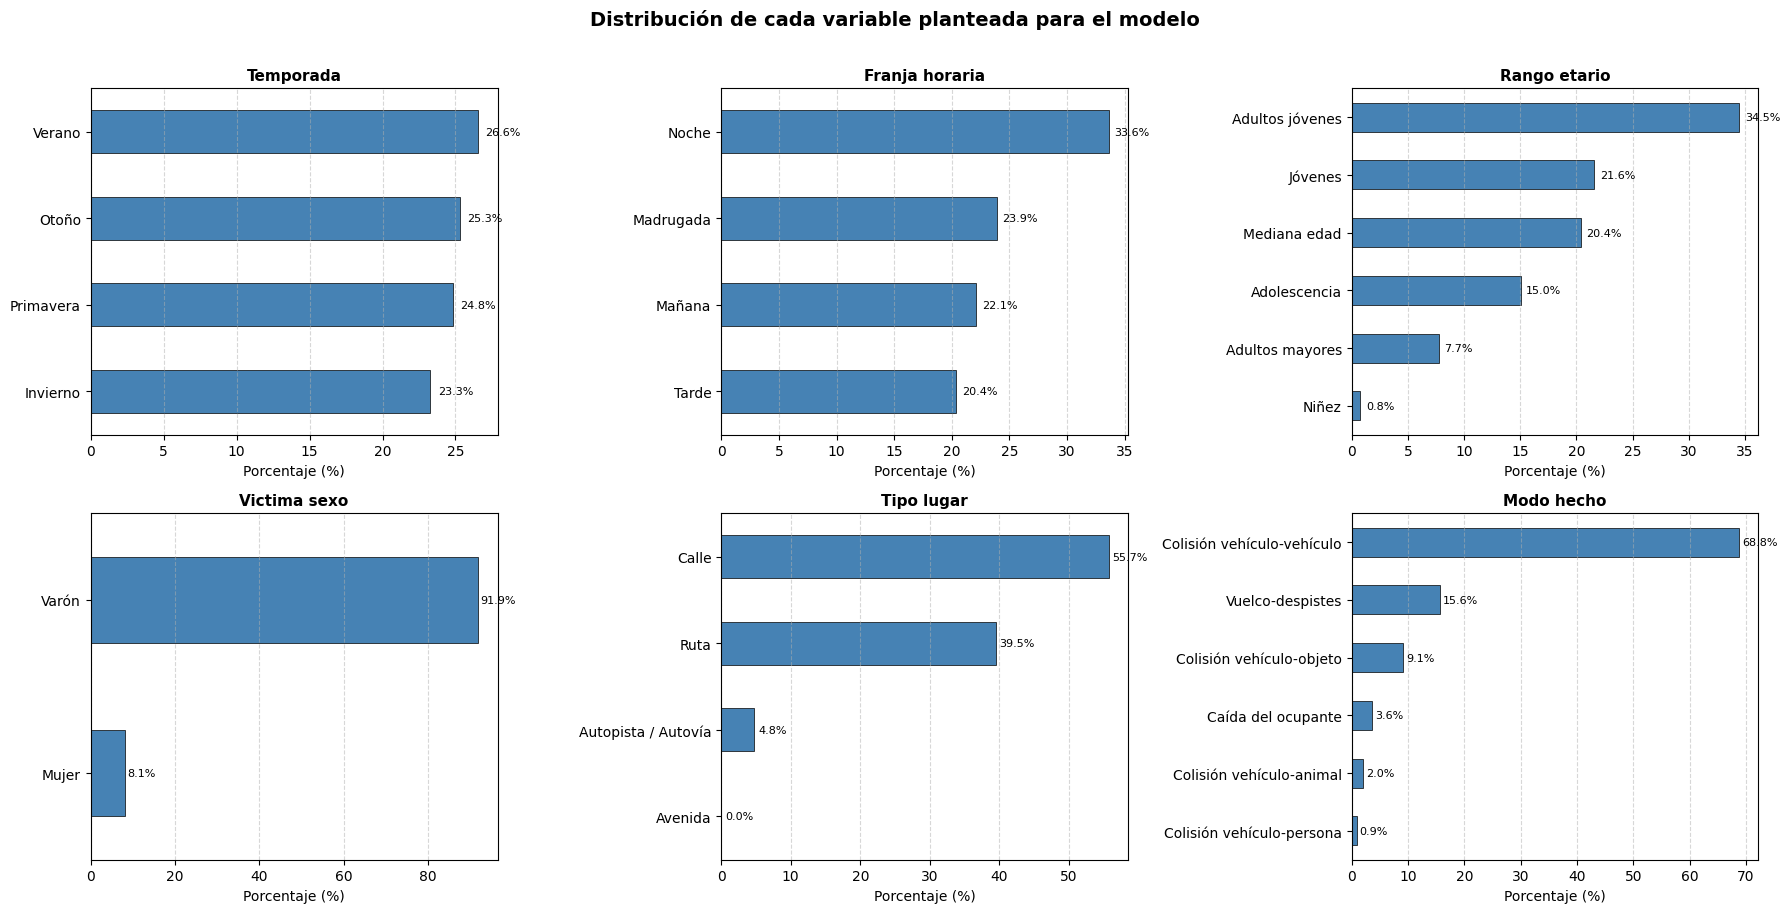

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.flatten()

for i, var in enumerate(variables_modelo):
    pct = df_cluster[var].value_counts(normalize=True).mul(100).sort_values(ascending=True)
    pct.plot(kind="barh", ax=axes[i], color="steelblue", edgecolor="black", linewidth=0.5)
    axes[i].set_title(var.replace("_", " ").capitalize(), fontsize=11, fontweight="bold")
    axes[i].set_xlabel("Porcentaje (%)")
    axes[i].set_ylabel("")
    axes[i].grid(axis="x", linestyle="--", alpha=0.5)
    for y, v in enumerate(pct.values):
        axes[i].text(v + 0.5, y, f"{v:.1f}%", va="center", fontsize=8)

plt.suptitle("Distribución de cada variable planteada para el modelo", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

Notamos posibles problemas con las variables "Victima_Sexo" y "Modo_hecho"

## SECCION 5: ELECCION DEL ALGORITMO

Dado que las variables que seleccionamos son categóricas (temporada, franja horaria, sexo, rango etario, modo de producción del hecho y tipo de lugar), optamos por usar el algoritmo de **K-Modes**, que utiliza modas (la categoría más frecuente) en lugar de promedios para agrupar los registros.

In [27]:
!pip install -q kmodes

¿En cuántos grupos ($k$) queremos dividir nuestros datos? Para tener una primera referencia usamos el **método del codo**.

Calculo de la inercia para cada valor de K ....
-> K = 2 procesado (Inercia: 7940.00)
-> K = 3 procesado (Inercia: 7098.00)
-> K = 4 procesado (Inercia: 6473.00)
-> K = 5 procesado (Inercia: 6267.00)
-> K = 6 procesado (Inercia: 6128.00)
-> K = 7 procesado (Inercia: 5928.00)


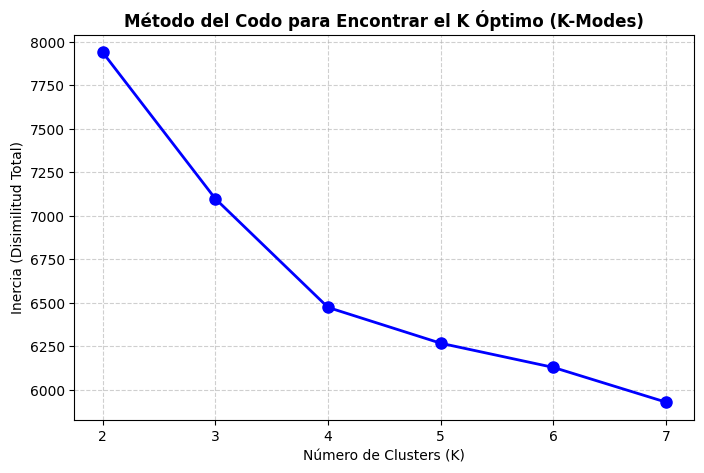

In [28]:
# Método del codo para K-MODES
from kmodes.kmodes import KModes

# Definimos el rango de valores de k que queremos probar (en nuestro caso, de 2 a 7)
k_range = range(2, 8)
inercancias = []

print("Calculo de la inercia para cada valor de K ....")

for k in k_range:

    km = KModes(n_clusters=k, init='Cao', n_init=5, random_state=42)

    # Ajustamos el modelo con los datos de clustering
    km.fit_predict(df_cluster.values)

    # Guardamos el costo/inercia (medida de disimilitud total dentro de los clusters)
    inercancias.append(km.cost_)
    print(f"-> K = {k} procesado (Inercia: {km.cost_:.2f})")

# Graficamos los resultados del Método del Codo
plt.figure(figsize=(8, 5))
plt.plot(k_range, inercancias, marker='o', linestyle='-', color='b', linewidth=2, markersize=8)
plt.title('Método del Codo para Encontrar el K Óptimo (K-Modes)', fontsize=12, fontweight='bold')
plt.xlabel('Número de Clusters (K)', fontsize=10)
plt.ylabel('Inercia (Disimilitud Total)', fontsize=10)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## SECCION 6: PRIMER MODELO — K-MODES (K = 4) CON LAS 6 VARIABLES ORIGINALES

Entrenamos el modelo con **todas** las variables que planteamos al inicio  y K = 4.

Para visualizarlo en un gráfico de dispersión aplicamos una técnica combinada:

- **One-Hot Encoding:** transformamos temporalmente las categorías en variables binarias (ceros y unos).
- **PCA (Análisis de Componentes Principales):** reducimos esa alta dimensionalidad binaria a solo 2 dimensiones principales (PC1 y PC2), lo que nos permite proyectar los registros en un plano 2D conservando la mayor cantidad de información posible.
- **Coloreo por cluster:** pintamos cada punto según el grupo asignado por K-Modes.

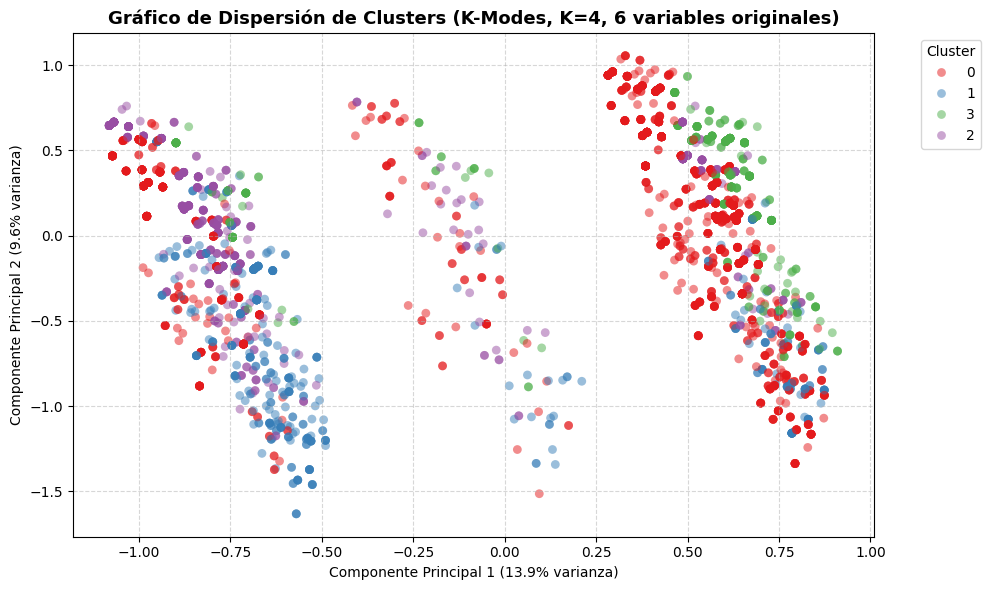


--- PERFILES / CENTROIDES DE CADA CLUSTER (K=4, 6 variables originales) ---


,temporada,franja_horaria,rango_etario,victima_sexo,tipo_lugar,modo_hecho
0,Verano,Noche,Adultos jóvenes,Varón,Calle,Colisión vehículo-vehículo
1,Otoño,Madrugada,Jóvenes,Varón,Ruta,Vuelco-despistes
2,Primavera,Mañana,Mediana edad,Varón,Ruta,Colisión vehículo-vehículo
3,Invierno,Tarde,Jóvenes,Varón,Calle,Colisión vehículo-vehículo


In [29]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.decomposition import PCA

k_optimo = 4
km = KModes(n_clusters=k_optimo, init='Cao', n_init=10, random_state=42)
clusters = km.fit_predict(df_cluster.values)

# Guardamos el resultado del cluster en una copia de trabajo
df_cluster_vis = df_cluster.copy()
df_cluster_vis['cluster'] = clusters

# Reducción de dimensionalidad para visualización en 2D (PCA sobre datos binarizados)
encoder = OneHotEncoder(sparse_output=False)
X_encoded = encoder.fit_transform(df_cluster)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_encoded)

# Creamos un DataFrame para graficar
df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['cluster'] = clusters.astype(str) # Convertimos a string para que seaborn los tome como categorías discretas

# Gráfico de Dispersión
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='cluster',
    data=df_pca,
    palette='Set1',
    alpha=0.5,
    s=40,
    edgecolor='none'
)

plt.title('Gráfico de Dispersión de Clusters (K-Modes, K=4, 6 variables originales)', fontsize=13, fontweight='bold')
plt.xlabel(f'Componente Principal 1 ({pca.explained_variance_ratio_[0]*100:.1f}% varianza)', fontsize=10)
plt.ylabel(f'Componente Principal 2 ({pca.explained_variance_ratio_[1]*100:.1f}% varianza)', fontsize=10)
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Mostramos las Modas (Centroides) de cada Cluster
print("\n--- PERFILES / CENTROIDES DE CADA CLUSTER (K=4, 6 variables originales) ---")
centroides_df = pd.DataFrame(km.cluster_centroids_, columns=df_cluster.columns)
display(centroides_df)

### 6.1 ¿Qué pasa con cada variable dentro de los clusters?

Miramos la composición porcentual de cada cluster para **todas** las variables del modelo, en particular `victima_sexo` y `temporada`. Observamos cuántas categorías distintas aparecen realmente representadas en cada cluster.

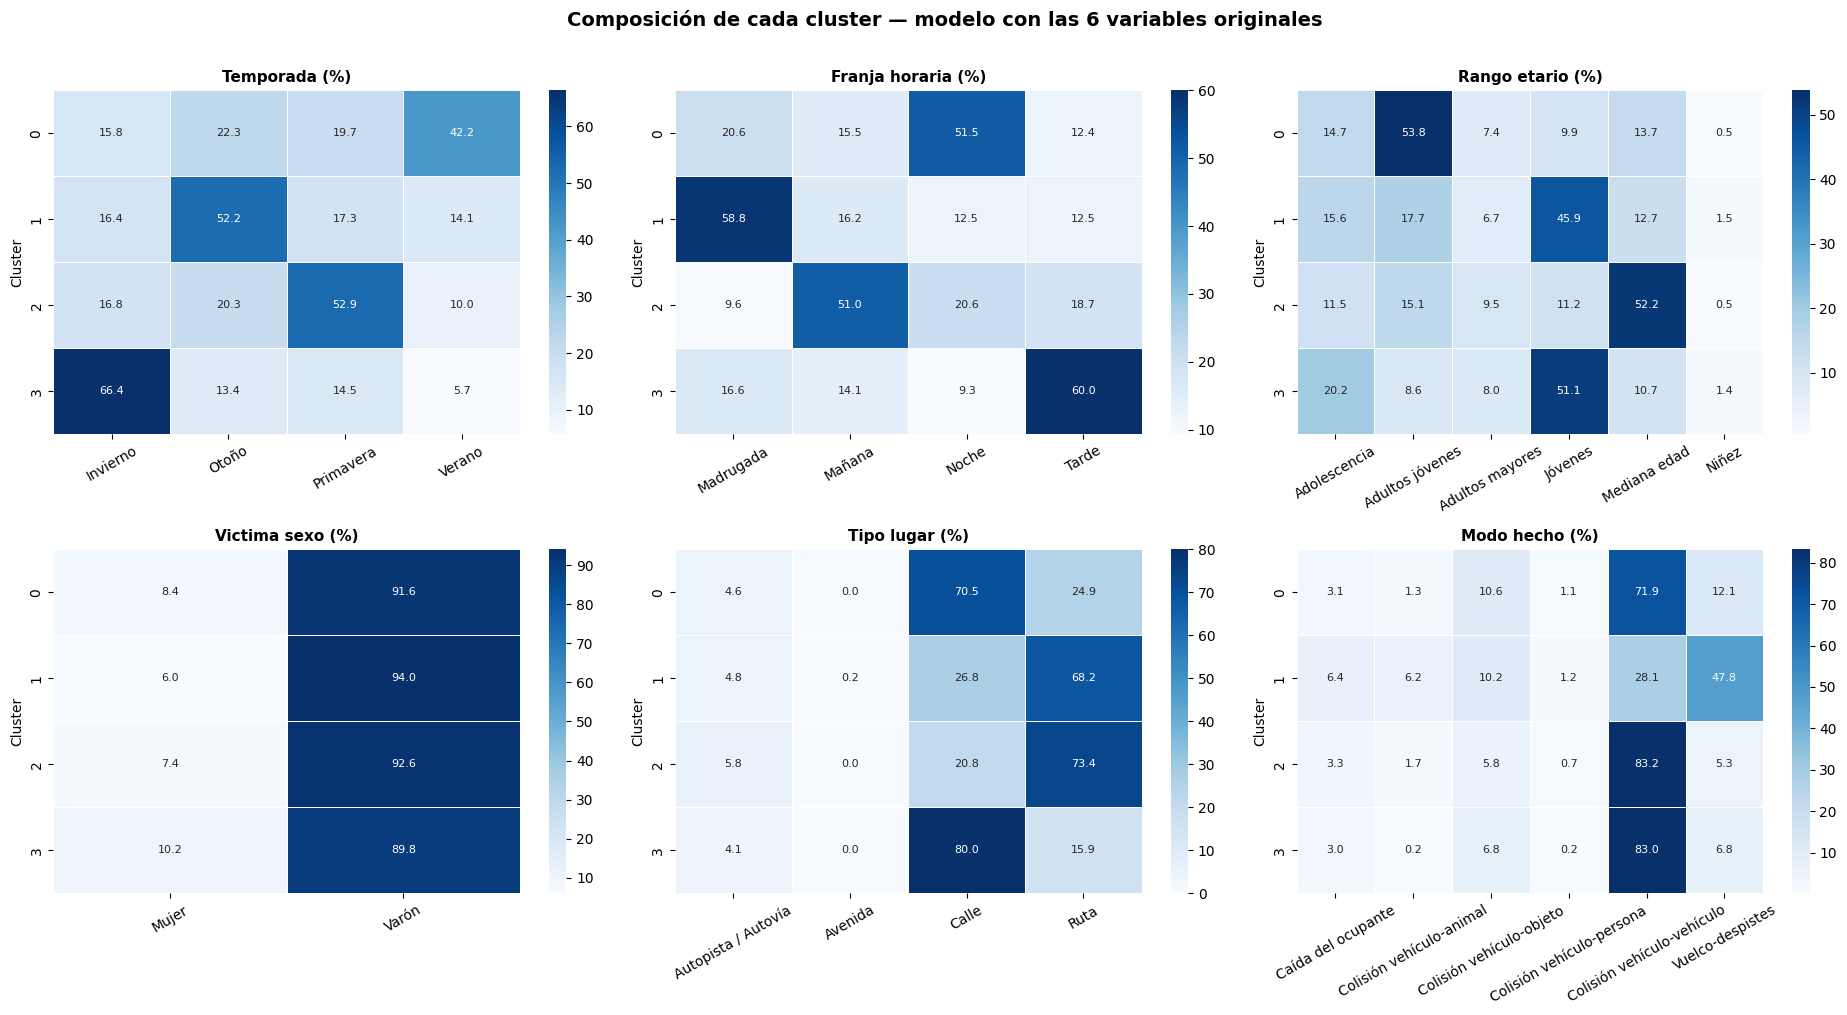

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(19, 10))
axes = axes.flatten()

for i, var in enumerate(variables_modelo):
    ct = pd.crosstab(df_cluster_vis['cluster'], df_cluster_vis[var], normalize='index') * 100
    sns.heatmap(ct, annot=True, fmt=".1f", cmap="Blues", ax=axes[i], linewidths=.5, annot_kws={"size": 8})
    axes[i].set_title(f"{var.replace('_', ' ').capitalize()} (%)", fontsize=11, fontweight='bold')
    axes[i].set_ylabel("Cluster")
    axes[i].set_xlabel("")
    axes[i].tick_params(axis='x', rotation=30)

plt.suptitle("Composición de cada cluster — modelo con las 6 variables originales", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 6.2 Métricas de referencia de este primer modelo

Calculamos la **silueta con distancia de Hamming** , el porcentaje de registros con silueta negativa (registros que estarían "mejor" en otro cluster) y el tamaño del cluster más grande. Guardamos estos números en una tabla (`tabla_modelos`) para poder compararlos con los modelos siguientes.

> El **método de la silueta** va de -1 a 1. Valores cercanos a 0 indican clusters superpuestos; negativos, registros mal asignados.

,Modelo,n,Silueta_Hamming,Pct_Negativos,Max_Cluster_%
0,"Modelo 1: 6 variables originales (Cao, K=4)",3092,0.0913,28.978,51.3907


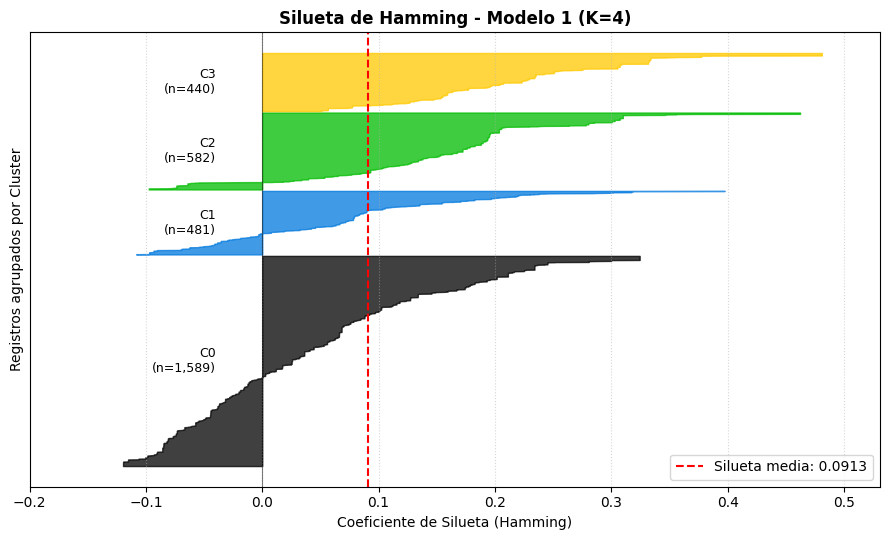

In [31]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

def metricas_particion(df_in, columnas, etiquetas):
    """Silueta de Hamming, % de siluetas negativas y tamaño del cluster mayoritario."""
    X_ord = OrdinalEncoder().fit_transform(df_in[columnas])
    ss = silhouette_samples(X_ord, etiquetas, metric="hamming")
    resumen = {
        "n": len(df_in),
        "Silueta_Hamming": ss.mean(),
        "Pct_Negativos": (ss < 0).mean() * 100,
        "Max_Cluster_%": pd.Series(etiquetas).value_counts(normalize=True).max() * 100,
    }
    return resumen, ss

def graficar_silueta(ss, etiquetas, titulo="Análisis de Silueta (Distancia de Hamming)"):
    """Genera el gráfico de silueta clásico a partir de los valores silhouette_samples."""
    etiquetas = np.asarray(etiquetas)
    clusters_unicos = np.sort(np.unique(etiquetas))
    n_clusters = len(clusters_unicos)
    silueta_media = ss.mean()

    fig, ax = plt.subplots(figsize=(9, 5.5))
    y_lower = 10

    for i, c in enumerate(clusters_unicos):
        # Extraer y ordenar los valores de silueta del cluster c
        valores_c = ss[etiquetas == c]
        valores_c.sort()

        tamano_c = valores_c.shape[0]
        y_upper = y_lower + tamano_c

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            valores_c,
            facecolor=color,
            edgecolor=color,
            alpha=0.75,
        )

        # Etiqueta con el número de cluster y su tamaño en el eje Y
        ax.text(-0.04, y_lower + 0.5 * tamano_c, f"C{c}\n(n={tamano_c:,})", va="center", ha="right", fontsize=9)
        y_lower = y_upper + 10  # Espacio entre bloques de clusters

    # Línea vertical con el promedio global de silueta
    ax.axvline(x=silueta_media, color="red", linestyle="--", linewidth=1.5, label=f"Silueta media: {silueta_media:.4f}")
    ax.axvline(x=0, color="black", linestyle="-", linewidth=0.8, alpha=0.5)

    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.set_xlabel("Coeficiente de Silueta (Hamming)")
    ax.set_ylabel("Registros agrupados por Cluster")
    ax.set_yticks([])  # Ocultamos ticks numéricos del eje Y porque mostramos las etiquetas de cluster
    ax.set_xlim([min(-0.2, ss.min() - 0.05), min(1.0, ss.max() + 0.05)])
    ax.legend(loc="lower right")
    ax.grid(axis="x", linestyle=":", alpha=0.5)

    plt.tight_layout()
    plt.show()

# 1. Calculamos métricas y capturamos 'ss' (antes estaba como '_')
m_base, ss_base = metricas_particion(df_cluster, variables_modelo, clusters)

tabla_modelos = pd.DataFrame([{"Modelo": "Modelo 1: 6 variables originales (Cao, K=4)", **m_base}])
display(tabla_modelos.round(4))

# 2. Graficamos la silueta
graficar_silueta(ss_base, clusters, titulo="Silueta de Hamming - Modelo 1 (K=4)")



En el gráfico de distribución (sección 4.1) y en los centroides del primer modelo vimos cómo se comporta `victima_sexo` y `tipo_lugar`. Si una categoría domina casi todo el dataset, la moda de esa variable va a ser la misma en todos los clusters, y entonces la variable casi no ayuda a diferenciar un grupo de otro.


## SECCION 7: DIAGNOSTICO DE ASOCIACION ENTRE VARIABLES (V DE CRAMÉR)

En vista de los resultados. Ahora damos un paso atrás y realizamos un analisis directamente a los datos: **¿qué tan relacionadas están las variables entre sí?** **¿Cuales pueden ser realmente utiles?**

Para variables categóricas usamos la **V de Cramér**, que va de 0 a 1:
- cercana a **0**: las dos variables son independientes (saber una no dice nada de la otra);
- cercana a **1**: están fuertemente asociadas (una casi determina a la otra).

Esto nos sirve para entender qué variables aportan información para separar perfiles y cuáles se comportan como "ruido", y para ver si hay variables redundantes. Incluimos también las variables derivadas que creamos en la sección 3 (`contraparte`, `turno`, `tipo_dia`, `ambito_vial`, `en_interseccion`).

Registros usados para el diagnóstico: 2,585


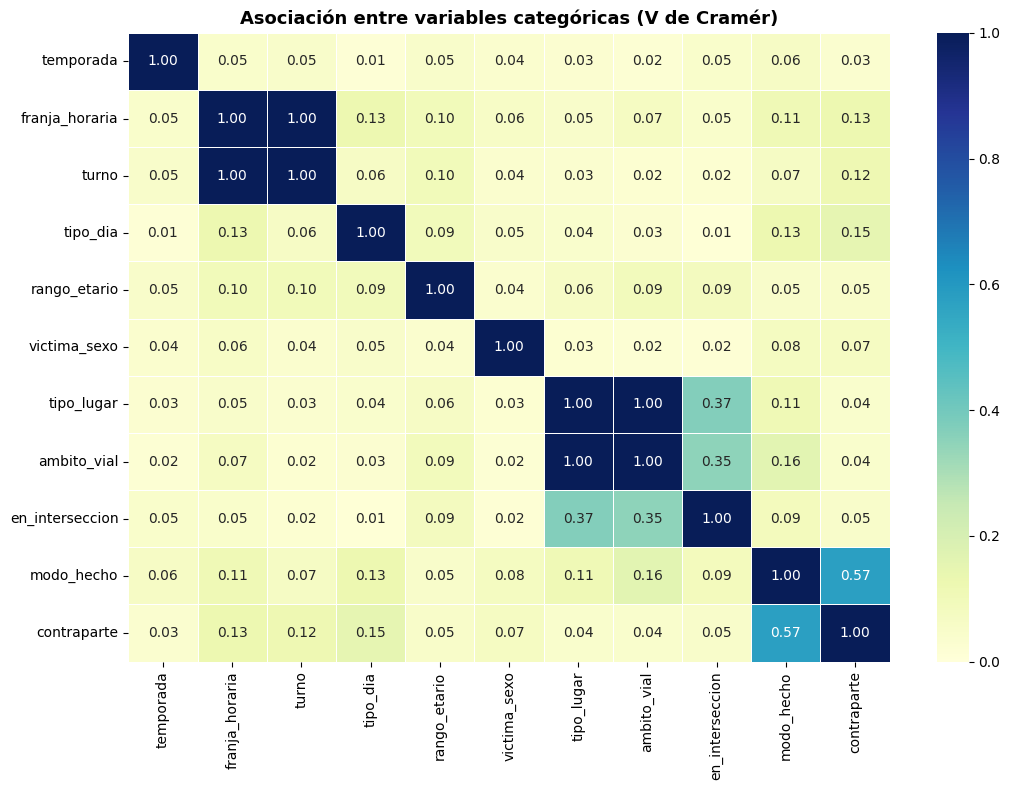

In [32]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct)[0]
    n = ct.sum().sum()
    r, k = ct.shape
    return np.sqrt((chi2 / n) / max(min(k - 1, r - 1), 1))

vars_diag = ["temporada", "franja_horaria", "turno", "tipo_dia", "rango_etario", "victima_sexo",
             "tipo_lugar", "ambito_vial", "en_interseccion", "modo_hecho", "contraparte"]

# Para medir asociación dejamos afuera las categorías "Sin determinar"
df_diag = df.copy()
for c in vars_diag:
    df_diag = df_diag[df_diag[c] != "Sin determinar"]
print(f"Registros usados para el diagnóstico: {len(df_diag):,}")

matriz_v = pd.DataFrame(
    [[cramers_v(df_diag[c1], df_diag[c2]) for c2 in vars_diag] for c1 in vars_diag],
    index=vars_diag,
    columns=vars_diag,
)

plt.figure(figsize=(11, 8))
sns.heatmap(matriz_v, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, linewidths=0.5)
plt.title("Asociación entre variables categóricas (V de Cramér)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

Análisis de Asociación (V de Cramér)El diagnóstico muestra cómo se relacionan las variables del dataset y qué conviene llevar al modelo K-Modes:


Variables redundantes: franja_horaria con turno y tipo_lugar con ambito_vial tienen dependencia total porque las derivadas son agrupaciones directas de las originales. No deben usarse juntas en el modelo para no duplicar su peso; conviene optar por las versiones agrupadas (turno y ambito_vial) para simplificar categorías.  


 Ejes que sí estructuran los perfiles: Las asociaciones más claras aparecen entre la mecánica del hecho y la contraparte del choque, y entre el ámbito vial y la presencia de intersección. Esto confirma que la combinación de infraestructura vial y dinámica del impacto es lo que mejor separa los distintos escenarios de siniestralidad.


   Variables que aportan ruido: temporada es prácticamente independiente de todo el resto del dataset, por lo que incluirla solo introduce ruido y empeora la cohesión de los clusters. Por su parte, victima_sexo y rango_etario tampoco muestran relación con las características físicas u horarias del siniestro, respaldando la decisión de dejarlas afuera del entrenamiento y usarlas solo como validación externa.
   
   
     Aporte del día de la semana: tipo_dia muestra una relación leve con el horario y el tipo de choque, ayudando a diferenciar la dinámica laboral de los días hábiles frente a los siniestros de fin de semana.   En resumen, para entrenar un buen modelo debemos descartar temporada, evitar variables duplicadas y concentrarnos en infraestructura vial, dinámica/contraparte del choque y contexto horario/día.

In [33]:
mv = matriz_v.copy()
np.fill_diagonal(mv.values, np.nan)

resumen_v = pd.DataFrame({
    "V_promedio": mv.mean(axis=1),
    "V_maxima": mv.max(axis=1),
    "Mas_asociada_con": mv.idxmax(axis=1),
}).sort_values("V_promedio")

display(resumen_v.round(3))

,V_promedio,V_maxima,Mas_asociada_con
temporada,0.039,0.063,modo_hecho
victima_sexo,0.043,0.076,modo_hecho
tipo_dia,0.070,0.152,contraparte
rango_etario,0.072,0.099,turno
en_interseccion,0.108,0.368,tipo_lugar
contraparte,0.126,0.574,modo_hecho
modo_hecho,0.143,0.574,contraparte
turno,0.152,1.000,franja_horaria
franja_horaria,0.174,1.000,turno
tipo_lugar,0.176,1.000,ambito_vial


## SECCION 8: PROBAMOS DISTINTOS CONJUNTOS DE VARIABLES

Con lo observado hasta acá, vamos a entrenar **el mismo algoritmo (K-Modes, K=4, init `Cao`)** sobre distintos conjuntos de variables y comparar métricas. Los escenarios van de lo que planteamos originalmente a conjuntos que incorporan lo que fuimos viendo (variables derivadas como `contraparte`, `turno`, `ambito_vial`, `en_interseccion`).

Para que la comparación sea justa, todos los escenarios se evalúan **sobre exactamente los mismos registros** (se descartan los que tienen "Sin determinar" en alguna de las variables involucradas).



In [34]:
escenarios = {
    "A. Originales (6 vars)":              ["temporada", "franja_horaria", "rango_etario", "victima_sexo", "tipo_lugar", "modo_hecho"],
    "B. Sin sexo":                         ["temporada", "franja_horaria", "rango_etario", "tipo_lugar", "modo_hecho"],
    "C. Sin sexo ni temporada":            ["franja_horaria", "rango_etario", "tipo_lugar", "modo_hecho"],
    "D. C + contraparte":                  ["franja_horaria", "rango_etario", "tipo_lugar", "modo_hecho", "contraparte"],
    "E. Derivadas atómicas":               ["ambito_vial", "en_interseccion", "contraparte", "turno"],
    "F. Derivadas atómicas + rango etario": ["ambito_vial", "en_interseccion", "contraparte", "turno", "rango_etario"],
}

# Base común: sin "Sin determinar" en ninguna de las variables usadas en algún escenario
vars_union = sorted(set(v for cols in escenarios.values() for v in cols))
df_base_comp = df.copy()
for c in vars_union:
    df_base_comp = df_base_comp[df_base_comp[c] != "Sin determinar"]
df_base_comp = df_base_comp.dropna(subset=vars_union).reset_index(drop=True)

print(f"Registros en la base común de comparación: {len(df_base_comp):,} (de {len(df):,})")
print("Variables involucradas:", vars_union)

Registros en la base común de comparación: 2,746 (de 3,092)
Variables involucradas: ['ambito_vial', 'contraparte', 'en_interseccion', 'franja_horaria', 'modo_hecho', 'rango_etario', 'temporada', 'tipo_lugar', 'turno', 'victima_sexo']


In [35]:
filas_esc = []
labels_esc = {}

for nombre, cols in escenarios.items():
    lab = KModes(n_clusters=4, init="Cao", n_init=10, random_state=42).fit_predict(df_base_comp[cols].values)
    m, _ = metricas_particion(df_base_comp, cols, lab)
    labels_esc[nombre] = lab
    filas_esc.append({"Escenario": nombre, "N_vars": len(cols), **m})

tabla_escenarios = pd.DataFrame(filas_esc)
display(tabla_escenarios.round(4))

,Escenario,N_vars,n,Silueta_Hamming,Pct_Negativos,Max_Cluster_%
0,A. Originales (6 vars),6,2746,0.0938,26.6205,57.8660
1,B. Sin sexo,5,2746,0.0878,31.7553,51.4567
2,C. Sin sexo ni temporada,4,2746,0.1543,24.2899,55.9723
3,D. C + contraparte,5,2746,0.1138,34.1952,53.5688
4,E. Derivadas atómicas,4,2746,0.1623,52.0393,56.5914
5,F. Derivadas atómicas + rango etario,5,2746,0.1461,24.4355,50.3277


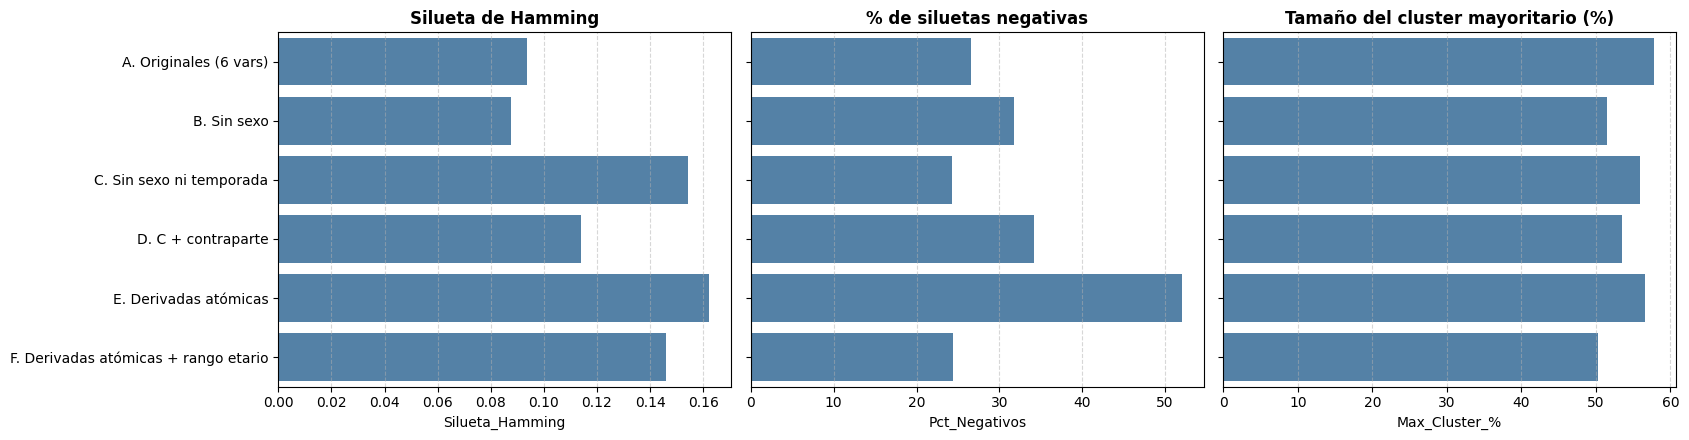

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (col, titulo) in zip(axes, [("Silueta_Hamming", "Silueta de Hamming"),
                                    ("Pct_Negativos", "% de siluetas negativas"),
                                    ("Max_Cluster_%", "Tamaño del cluster mayoritario (%)")]):
    sns.barplot(data=tabla_escenarios, y="Escenario", x=col, ax=ax, color="steelblue")
    ax.set_title(titulo, fontweight="bold")
    ax.set_ylabel("")
    ax.grid(axis="x", linestyle="--", alpha=0.5)
axes[1].set_yticklabels([]); axes[2].set_yticklabels([])
plt.tight_layout()
plt.show()

### 8.1 ¿Cuánto aporta cada variable a separar los clusters? (por escenario)

Para cada escenario medimos, con la V de Cramér, qué tan asociada está **cada variable con el cluster asignado**. Si una variable tiene V cercana a 0 con el cluster, el algoritmo prácticamente no la está usando para separar los grupos.

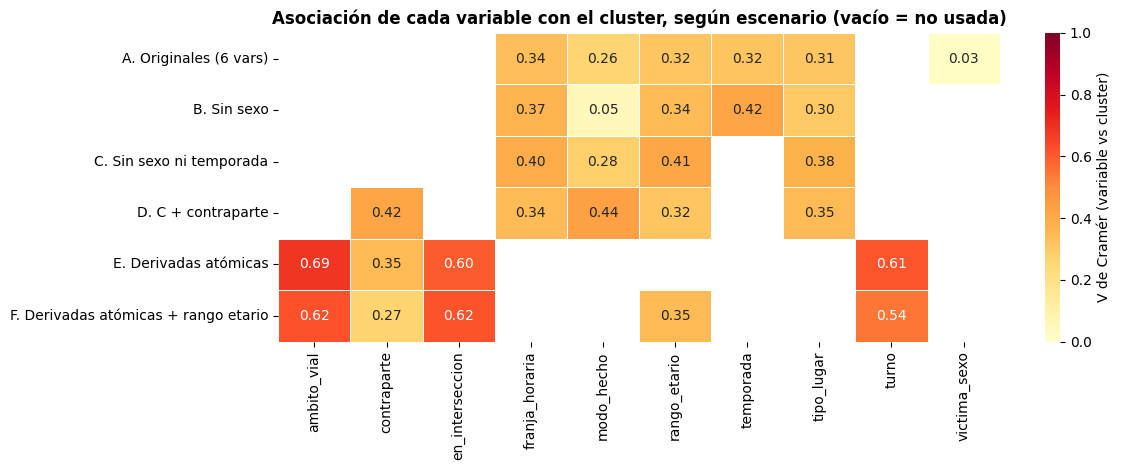

In [37]:
filas_aporte = []
for nombre, cols in escenarios.items():
    fila = {"Escenario": nombre}
    for c in vars_union:
        fila[c] = cramers_v(df_base_comp[c], labels_esc[nombre]) if c in cols else np.nan
    filas_aporte.append(fila)

tabla_aporte = pd.DataFrame(filas_aporte).set_index("Escenario")

plt.figure(figsize=(12, 4.8))
sns.heatmap(tabla_aporte, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1, linewidths=0.5,
            cbar_kws={"label": "V de Cramér (variable vs cluster)"}, mask=tabla_aporte.isna())
plt.title("Asociación de cada variable con el cluster, según escenario (vacío = no usada)", fontweight="bold")
plt.ylabel("")
plt.tight_layout()
plt.show()

## SECCION 9: ¿SIRVEN LAS VARIABLES COMPUESTAS?

En la sección 3.10 creamos dos variables que combinan otras:
- `perfil_vial` = `ambito_vial` + `en_interseccion`
- `escenario_temporal` = `tipo_dia` + `turno`

La idea de una variable compuesta es resumir dos columnas en una. El problema potencial con K-Modes es la distancia: con columnas separadas, dos registros que coinciden en el ámbito vial pero no en la intersección están "a mitad de camino"; con la variable compuesta pasan a ser simplemente "distintos". Lo comprobamos empíricamente comparando **la misma información** de forma atómica vs compuesta.

In [38]:
vars_atomicas   = ["ambito_vial", "en_interseccion", "turno", "tipo_dia", "contraparte"]
vars_compuestas = ["perfil_vial", "escenario_temporal", "contraparte"]

df_comp_sub = df_base_comp.copy()
for c in vars_atomicas + vars_compuestas:
    df_comp_sub = df_comp_sub[df_comp_sub[c] != "Sin determinar"]
df_comp_sub = df_comp_sub.reset_index(drop=True)
print(f"Registros usados en esta comparación: {len(df_comp_sub):,}")

filas_comp = []
for nombre, cols in [("Atómicas (5 columnas)", vars_atomicas), ("Compuestas (3 columnas)", vars_compuestas)]:
    lab = KModes(n_clusters=4, init="Huang", n_init=30, random_state=42).fit_predict(df_comp_sub[cols].values)
    m, _ = metricas_particion(df_comp_sub, cols, lab)
    filas_comp.append({"Variables": nombre, **m})

display(pd.DataFrame(filas_comp).round(4))

Registros usados en esta comparación: 2,585


,Variables,n,Silueta_Hamming,Pct_Negativos,Max_Cluster_%
0,Atómicas (5 columnas),2585,0.2813,7.6209,32.6499
1,Compuestas (3 columnas),2585,0.2174,14.9323,36.4023


> Nota: la comparación tiene una limitación: las variables atómicas son 5 columnas y las compuestas 3, y la distancia de Hamming se normaliza por la cantidad de columnas. Lo tomamos como indicio, no como prueba.

## SECCION 10: DEFINICION DE LAS VARIABLES FINALES DEL MODELO

Con todo lo visto (distribución de cada variable, V de Cramér, comparación de escenarios y variables compuestas), definimos el conjunto de variables para el modelo definitivo.

El conjunto por defecto que dejamos acá son las **4 variables derivadas atómicas** (`ambito_vial`, `en_interseccion`, `contraparte`, `turno`), que corresponde al escenario **E**. **Pueden cambiarlo editando la lista** `variables_finales` si, mirando los resultados de la sección 11, prefieren otro escenario.

Un punto a decidir como grupo: el objetivo del proyecto plantea **validación externa sobre edad, género y región**. Las variables que **no** entren al modelo (por ejemplo `victima_sexo` o `rango_etario`) pueden usarse justamente para esa validación en la sección 17. Si una variable entra al modelo, ya no sirve como validación independiente.

In [39]:
# ======== EDITABLE ========
variables_finales = ["ambito_vial", "en_interseccion", "contraparte", "turno"]
# Ejemplo de alternativa: ["franja_horaria", "rango_etario", "tipo_lugar", "modo_hecho", "contraparte"]
# ==========================

df_modelo = df.copy()
for col in variables_finales:
    df_modelo = df_modelo[df_modelo[col] != "Sin determinar"]
df_modelo = df_modelo.dropna(subset=variables_finales).reset_index(drop=True)

print(f"Dataset final para modelado: {len(df_modelo):,} registros")
for col in variables_finales:
    print(f"  - {col}: {(df_modelo[col].value_counts(normalize=True)*100).round(1).to_dict()}")

X_ord = OrdinalEncoder().fit_transform(df_modelo[variables_finales])
X_ohe = OneHotEncoder(sparse_output=False).fit_transform(df_modelo[variables_finales])

Dataset final para modelado: 2,746 registros
  - ambito_vial: {'Urbano (Calle/Av.)': 58.0, 'Vía rápida (Ruta/Autop.)': 42.0}
  - en_interseccion: {'En intersección': 70.2, 'Tramo / Sin intersección': 29.8}
  - contraparte: {'Auto / Camioneta': 40.6, 'Sin tercero (despiste/objeto)': 34.1, 'Vehículo pesado': 16.5, 'Moto / Bici': 8.8}
  - turno: {'Nocturno (18-06h)': 56.4, 'Diurno (06-18h)': 43.6}


## SECCION 11: ELECCION DEL NUMERO DE CLUSTERS (K) CON VARIAS METRICAS

Antes habíamos usado el método del codo. Ahora, sobre las variables finales, barremos K = 2 a 6 y miramos **dos** cosas: la silueta de Hamming y el tamaño del cluster mayoritario (si un cluster concentra más de la mitad de los registros, se vuelve una "bolsa" poco informativa).

Comparamos tres variantes:
- **K-Modes con `Cao`** (inicialización determinística),
- **K-Modes con `Huang`** (inicialización aleatoria, con varios reinicios),
- **One-Hot + K-Means** (convertir a binario y usar distancia euclídea).

In [40]:
from sklearn.cluster import KMeans

N_INIT_SCAN = 10
rows_k = []

for k in range(2, 7):
    lc = KModes(n_clusters=k, init="Cao", n_init=N_INIT_SCAN, random_state=42).fit_predict(df_modelo[variables_finales].values)
    lh = KModes(n_clusters=k, init="Huang", n_init=N_INIT_SCAN, random_state=42).fit_predict(df_modelo[variables_finales].values)
    lo = KMeans(n_clusters=k, n_init=N_INIT_SCAN, random_state=42).fit_predict(X_ohe)

    for nombre, lab in [("K-Modes (Cao)", lc), ("K-Modes (Huang)", lh), ("OHE + K-Means", lo)]:
        rows_k.append({
            "Modelo": nombre, "K": k,
            "Silueta_Hamming": silhouette_score(X_ord, lab, metric="hamming"),
            "Max_Cluster_%": pd.Series(lab).value_counts(normalize=True).max() * 100,
        })

df_scan_k = pd.DataFrame(rows_k)
display(df_scan_k.pivot(index="K", columns="Modelo", values=["Silueta_Hamming", "Max_Cluster_%"]).round(3))

Silueta_Hamming                               Max_Cluster_%  \
Modelo   K-Modes (Cao) K-Modes (Huang) OHE + K-Means K-Modes (Cao)   
K                                                                    
2                0.323           0.261         0.418        76.402   
3                0.190           0.289         0.392        63.765   
4                0.162           0.321         0.467        56.591   
5                0.186           0.365         0.445        52.840   
6                0.204           0.357         0.440        48.762   

                                      
Modelo K-Modes (Huang) OHE + K-Means  
K                                     
2               56.009        58.012  
3               44.465        41.988  
4               43.955        32.229  
5               28.186        31.027  
6               26.074        23.853

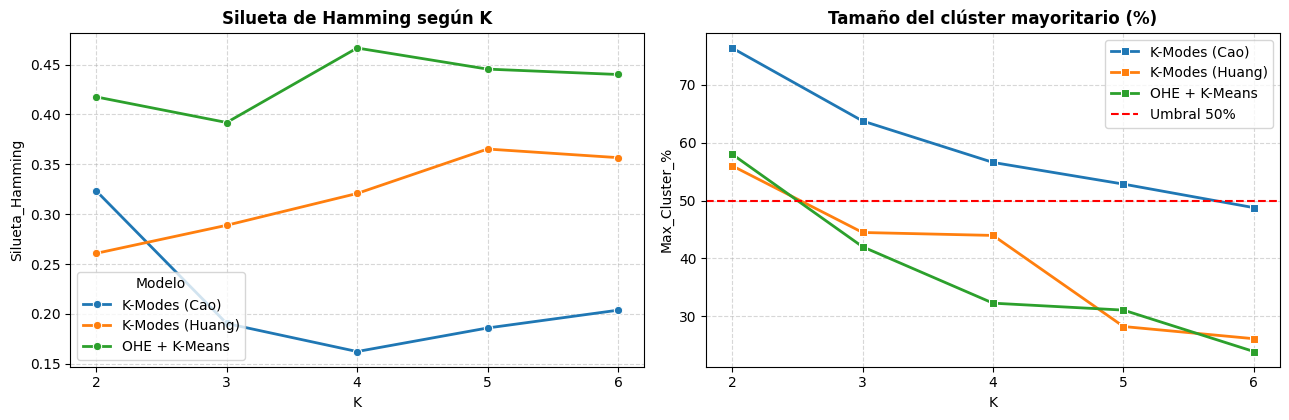

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
sns.lineplot(data=df_scan_k, x="K", y="Silueta_Hamming", hue="Modelo", marker="o", ax=axes[0], linewidth=2)
axes[0].set_title("Silueta de Hamming según K", fontweight="bold")
axes[0].set_xticks(range(2, 7))
axes[0].grid(True, linestyle="--", alpha=0.5)

sns.lineplot(data=df_scan_k, x="K", y="Max_Cluster_%", hue="Modelo", marker="s", ax=axes[1], linewidth=2)
axes[1].axhline(50, color="red", linestyle="--", label="Umbral 50%")
axes[1].set_title("Tamaño del clúster mayoritario (%)", fontweight="bold")
axes[1].set_xticks(range(2, 7))
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()

In [42]:
# ======== EDITABLE ========
K_FINAL = 4
# ==========================
print("K elegido para el resto del análisis:", K_FINAL)

K elegido para el resto del análisis: 4


## SECCION 12: COMPARATIVA DE METODOLOGIAS (MISMO K, MISMAS VARIABLES)

Para decidir qué enfoque usar para el modelo definitivo, comparamos distintas estrategias sobre el mismo conjunto de variables y el mismo K. Cada una en su propia celda.

Dos aclaraciones conceptuales:
- **Boosting / Random Forest son aprendizaje supervisado:** necesitan una etiqueta $y$, así que no sirven para *descubrir* grupos. Sí pueden usarse *después*, como auditor: entrenar un clasificador para predecir el cluster y medir qué variables pesan realmente (importancia por permutación).
- **Ensamble (Consensus Clustering)** y **Autoencoder** son alternativas no supervisadas que podemos probar.

Vamos guardando los resultados en `res_bench` y `labels_bench`.

In [43]:
res_bench = {}
labels_bench = {}

def registrar(nombre, etiquetas):
    m, ss = metricas_particion(df_modelo, variables_finales, etiquetas)
    res_bench[nombre] = m
    labels_bench[nombre] = etiquetas
    print(f"{nombre}: Silueta={m['Silueta_Hamming']:.4f} | %Neg={m['Pct_Negativos']:.1f}% | Max cluster={m['Max_Cluster_%']:.1f}%")

### 12.1 K-Modes con inicialización `Cao`

In [44]:
lab_cao = KModes(n_clusters=K_FINAL, init="Cao", n_init=10, random_state=42).fit_predict(df_modelo[variables_finales].values)
registrar("K-Modes (Cao)", lab_cao)

K-Modes (Cao): Silueta=0.1623 | %Neg=52.0% | Max cluster=56.6%


### 12.2 K-Modes con inicialización `Huang` (30 reinicios)

In [45]:
km_huang = KModes(n_clusters=K_FINAL, init="Huang", n_init=30, random_state=42)
lab_huang = km_huang.fit_predict(df_modelo[variables_finales].values)
registrar("K-Modes (Huang, n_init=30)", lab_huang)

K-Modes (Huang, n_init=30): Silueta=0.4071 | %Neg=0.0% | Max cluster=29.4%


### 12.3 One-Hot Encoding + K-Means

In [46]:
lab_ohe = KMeans(n_clusters=K_FINAL, n_init=30, random_state=42).fit_predict(X_ohe)
registrar("OHE + K-Means", lab_ohe)

OHE + K-Means: Silueta=0.4665 | %Neg=0.0% | Max cluster=32.2%


### 12.4 Ensamble no supervisado (Consensus Clustering)

Corremos K-Modes `Huang` con 5 semillas distintas, apilamos las 5 particiones (codificadas en One-Hot) y las volvemos a agrupar con K-Means. Busca reducir la dependencia de la inicialización aleatoria.

In [47]:
particiones = [
    KModes(n_clusters=K_FINAL, init="Huang", n_init=20, random_state=s).fit_predict(df_modelo[variables_finales].values)
    for s in [11, 22, 33, 44, 55]
]
P_cons = OneHotEncoder(sparse_output=False).fit_transform(np.column_stack(particiones))
lab_cons = KMeans(n_clusters=K_FINAL, n_init=30, random_state=42).fit_predict(P_cons)
registrar("Ensamble (Consensus Clustering)", lab_cons)

Ensamble (Consensus Clustering): Silueta=0.3885 | %Neg=2.8% | Max cluster=37.9%


### 12.5 Red neuronal: Autoencoder (MLP) + K-Means

Entrenamos una red que comprime los datos One-Hot a un espacio latente de 4 dimensiones y luego intenta reconstruirlos (`MLPRegressor` con capas 16-4-16). Después agrupamos con K-Means en ese espacio latente.

In [48]:
from sklearn.neural_network import MLPRegressor

ae = MLPRegressor(hidden_layer_sizes=(16, 4, 16), activation="relu", max_iter=300, random_state=42, early_stopping=True)
ae.fit(X_ohe, X_ohe)

# Espacio latente: salida de la capa de 4 neuronas (cuello de botella)
h1 = np.maximum(0, X_ohe @ ae.coefs_[0] + ae.intercepts_[0])
Z_lat = np.maximum(0, h1 @ ae.coefs_[1] + ae.intercepts_[1])

lab_ae = KMeans(n_clusters=K_FINAL, n_init=30, random_state=42).fit_predict(Z_lat)
registrar("Autoencoder (MLP) + K-Means", lab_ae)

Autoencoder (MLP) + K-Means: Silueta=0.3547 | %Neg=2.7% | Max cluster=29.8%


### 12.6 Tabla comparativa de métricas

In [49]:
tabla_bench = pd.DataFrame(res_bench).T.reset_index().rename(columns={"index": "Estrategia"})
display(tabla_bench.round(4))

,Estrategia,n,Silueta_Hamming,Pct_Negativos,Max_Cluster_%
0,K-Modes (Cao),2746.0,0.1623,52.0393,56.5914
1,"K-Modes (Huang, n_init=30)",2746.0,0.4071,0.0000,29.3518
2,OHE + K-Means,2746.0,0.4665,0.0000,32.2287
3,Ensamble (Consensus Clustering),2746.0,0.3885,2.8041,37.8733
4,Autoencoder (MLP) + K-Means,2746.0,0.3547,2.6584,29.7888


### 12.7 Auditoría con Boosting: ¿qué variables usa realmente cada partición?

Para cada partición entrenamos un `HistGradientBoostingClassifier` que intenta **predecir el cluster** a partir de las variables, y medimos la **importancia por permutación** de cada variable (cuánto empeora la predicción si se la "mezcla"). Una variable con importancia cercana a 0 casi no participa en la separación de los grupos.

Además de la importancia, el accuracy del clasificador indica qué tan "explicables" por las variables son los clusters.

,ambito_vial,en_interseccion,contraparte,turno,Accuracy_test
K-Modes (Cao),0.259,0.163,0.284,0.279,1.0
"K-Modes (Huang, n_init=30)",0.456,0.152,0.124,0.395,1.0
OHE + K-Means,0.485,0.000,0.000,0.488,1.0
Ensamble (Consensus Clustering),0.248,0.193,0.157,0.493,1.0
Autoencoder (MLP) + K-Means,0.337,0.417,0.238,0.000,1.0


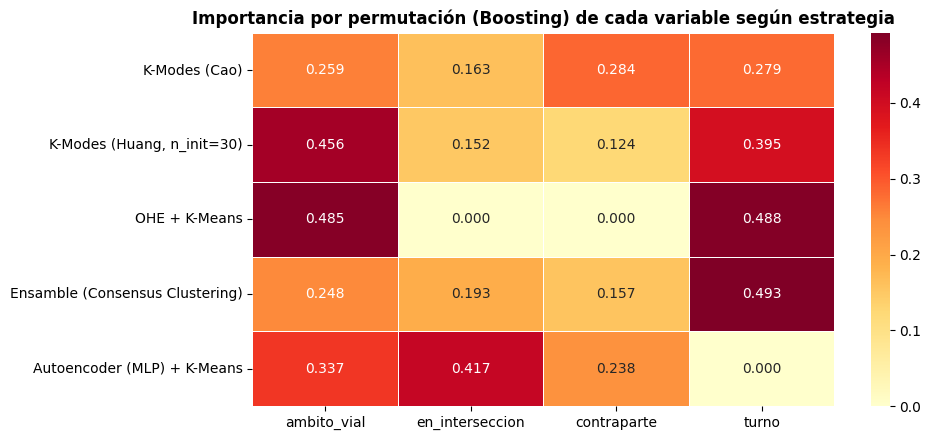

In [50]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

def auditar(labels):
    X_tr, X_te, y_tr, y_te = train_test_split(X_ord, labels, test_size=0.25, random_state=42, stratify=labels)
    clf = HistGradientBoostingClassifier(categorical_features=list(range(len(variables_finales))), random_state=42).fit(X_tr, y_tr)
    perm = permutation_importance(clf, X_te, y_te, n_repeats=5, random_state=42)
    fila = {col: float(v) for col, v in zip(variables_finales, perm.importances_mean)}
    fila["Accuracy_test"] = clf.score(X_te, y_te)
    return fila

tabla_importancias = pd.DataFrame({nombre: auditar(lab) for nombre, lab in labels_bench.items()}).T
display(tabla_importancias.round(3))

plt.figure(figsize=(10, 4.5))
sns.heatmap(tabla_importancias[variables_finales], annot=True, fmt=".3f", cmap="YlOrRd", linewidths=0.5)
plt.title("Importancia por permutación (Boosting) de cada variable según estrategia", fontweight="bold")
plt.tight_layout()
plt.show()

## SECCION 13: MODELO DEFINITIVO — K-MODES

Como el objetivo del proyecto es un **clustering categórico con K-Modes**, el modelo definitivo es K-Modes. Elegimos la inicialización y la cantidad de reinicios mirando la comparativa de la sección 15 (ambos parámetros se pueden editar abajo).

In [51]:
# ======== EDITABLE ========
INIT_FINAL = "Huang"      # "Huang" o "Cao"
N_INIT_FINAL = 30
# ==========================

km_final = KModes(n_clusters=K_FINAL, init=INIT_FINAL, n_init=N_INIT_FINAL, random_state=42)
lab_final = km_final.fit_predict(df_modelo[variables_finales].values)

ss_final = silhouette_samples(X_ord, lab_final, metric="hamming")
df_modelo["cluster"] = lab_final
df_modelo["silhouette_score"] = ss_final

print(f"Modelo definitivo: K-Modes (init={INIT_FINAL}, n_init={N_INIT_FINAL}, K={K_FINAL})")
print(f"Silueta de Hamming global: {ss_final.mean():.4f}")
print(f"% de siluetas negativas : {(ss_final < 0).mean()*100:.1f}%")

Modelo definitivo: K-Modes (init=Huang, n_init=30, K=4)
Silueta de Hamming global: 0.4071
% de siluetas negativas : 0.0%


### 13.1 Proyección PCA y silueta por cluster

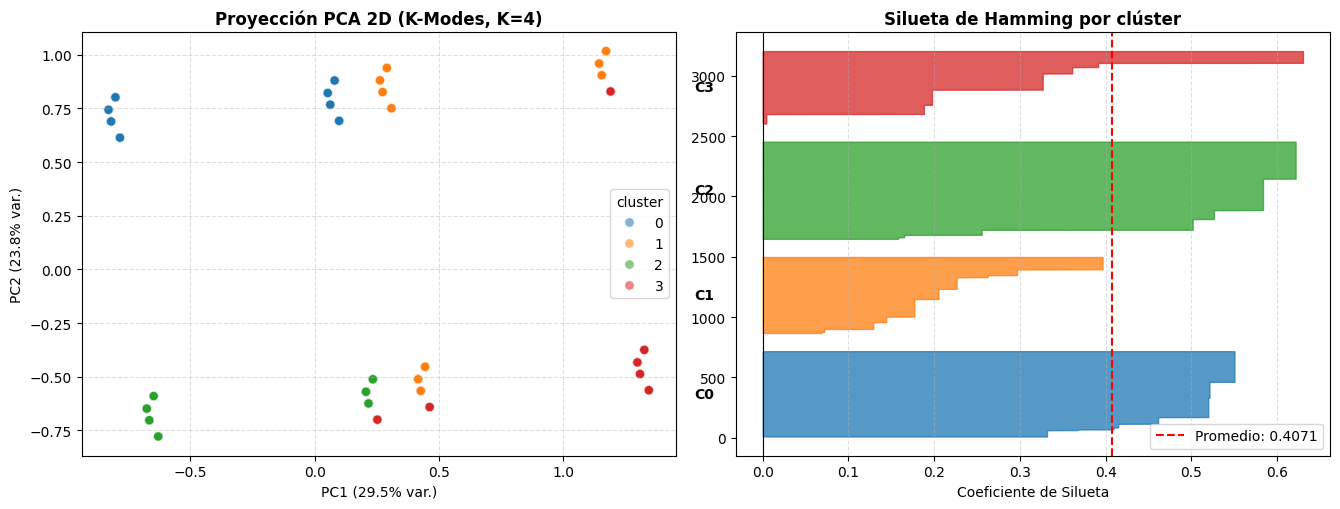

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

# PCA 2D
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_ohe)
df_pca = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
df_pca["cluster"] = df_modelo["cluster"].astype(str)

sns.scatterplot(
    data=df_pca, x="PC1", y="PC2", hue="cluster",
    hue_order=[str(i) for i in range(K_FINAL)], palette="tab10", alpha=0.55, s=45, ax=axes[0]
)
axes[0].set_title(f"Proyección PCA 2D (K-Modes, K={K_FINAL})", fontweight="bold")
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var.)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var.)")
axes[0].grid(True, linestyle="--", alpha=0.4)

# Silueta por clúster
y_lower = 10
for i in range(K_FINAL):
    vals = np.sort(ss_final[lab_final == i])
    y_upper = y_lower + len(vals)
    color = plt.cm.tab10(i / 10)
    axes[1].fill_betweenx(np.arange(y_lower, y_upper), 0, vals, facecolor=color, edgecolor=color, alpha=0.75)
    axes[1].text(-0.08, y_lower + 0.5 * len(vals), f"C{i}", fontweight="bold", va="center")
    y_lower = y_upper + 150

axes[1].axvline(x=ss_final.mean(), color="red", linestyle="--", label=f"Promedio: {ss_final.mean():.4f}")
axes[1].axvline(x=0, color="black", linewidth=0.8)
axes[1].set_title("Silueta de Hamming por clúster", fontweight="bold")
axes[1].set_xlabel("Coeficiente de Silueta")
axes[1].legend(loc="lower right")
axes[1].grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### 13.2 Tamaño, calidad y perfiles (modas) de cada cluster

In [53]:
resumen_final = (
    df_modelo.groupby("cluster")
    .agg(
        Cantidad_Registros=("silhouette_score", "count"),
        Silhouette_Promedio=("silhouette_score", "mean"),
        Pct_Negativos=("silhouette_score", lambda s: (s < 0).mean() * 100),
    )
    .reset_index()
)
resumen_final["Porcentaje_Total"] = resumen_final["Cantidad_Registros"] / len(df_modelo) * 100
display(resumen_final.round(4))

print("\nCentroides modales (K-Modes):")
display(pd.DataFrame(km_final.cluster_centroids_, columns=variables_finales))

,cluster,Cantidad_Registros,Silhouette_Promedio,Pct_Negativos,Porcentaje_Total
0,0,708,0.5038,0.0,25.7830
1,1,631,0.2230,0.0,22.9789
2,2,806,0.5492,0.0,29.3518
3,3,601,0.2958,0.0,21.8864



Centroides modales (K-Modes):


,ambito_vial,en_interseccion,contraparte,turno
0,Urbano (Calle/Av.),En intersección,Auto / Camioneta,Diurno (06-18h)
1,Vía rápida (Ruta/Autop.),En intersección,Auto / Camioneta,Diurno (06-18h)
2,Urbano (Calle/Av.),En intersección,Auto / Camioneta,Nocturno (18-06h)
3,Vía rápida (Ruta/Autop.),Tramo / Sin intersección,Sin tercero (despiste/objeto),Nocturno (18-06h)


### 13.3 Estabilidad (ARI) del modelo definitivo

Repetimos el ajuste con distintas semillas y comparamos cada partición contra la del modelo definitivo. (Si `INIT_FINAL = "Cao"`, el resultado es determinístico y el ARI será 1 trivialmente; en ese caso conviene medir estabilidad con `Huang`.)

In [54]:
semillas_ari = [7, 19, 99, 123]
aris_final = []
for s in semillas_ari:
    lab_s = KModes(n_clusters=K_FINAL, init="Huang", n_init=N_INIT_FINAL, random_state=s).fit_predict(df_modelo[variables_finales].values)
    aris_final.append(adjusted_rand_score(lab_final, lab_s))

print(f"ARI vs. modelo definitivo | semillas {semillas_ari}: {[round(a, 3) for a in aris_final]}")
print(f"ARI promedio: {np.mean(aris_final):.3f}")

ARI vs. modelo definitivo | semillas [7, 19, 99, 123]: [0.349, 0.369, 0.685, 0.291]
ARI promedio: 0.423


## SECCION 14: COMPOSICION DE LOS CLUSTERS Y VALIDACION EXTERNA

### 14.1 Composición interna (variables del modelo)

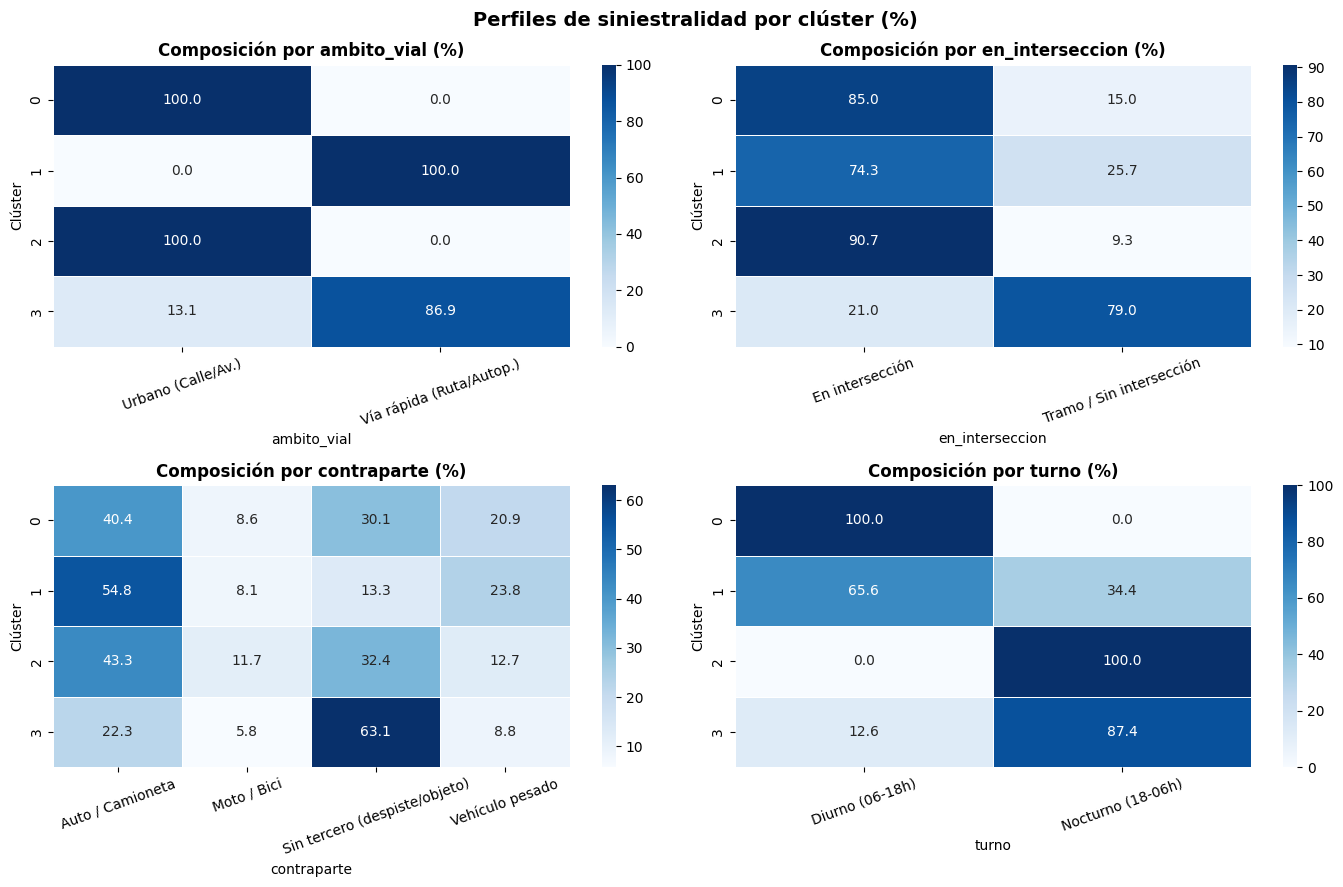

In [55]:
n_vars = len(variables_finales)
n_cols = 2
n_rows = int(np.ceil(n_vars / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4.5 * n_rows))
axes = np.array(axes).flatten()

for idx, var in enumerate(variables_finales):
    ct = pd.crosstab(df_modelo["cluster"], df_modelo[var], normalize="index") * 100
    sns.heatmap(ct, annot=True, fmt=".1f", cmap="Blues", ax=axes[idx], linewidths=0.5)
    axes[idx].set_title(f"Composición por {var} (%)", fontweight="bold")
    axes[idx].set_ylabel("Clúster")
    axes[idx].tick_params(axis="x", rotation=20)

for j in range(n_vars, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Perfiles de siniestralidad por clúster (%)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 14.2 Validación externa

Cruzamos los clusters contra variables **que no se usaron para construirlos**: edad, género y región. Para cada una calculamos un test Chi² de independencia (¿la distribución de esa variable cambia entre clusters?) y la V de Cramér como medida del tamaño de la asociación (el p-valor por sí solo se vuelve muy chico con muchos datos, así que conviene mirar ambos).

El código elige automáticamente, entre `grupo_edad_3`, `rango_etario`, `victima_sexo` y `region`, **solo las que no están en `variables_finales`**.

In [56]:
candidatas_ext = ["grupo_edad_3", "rango_etario", "victima_sexo", "region"]
vars_externas = [c for c in candidatas_ext if c not in variables_finales]
print("Variables de validación externa:", vars_externas)

resumen_ext = []
for ext_col in vars_externas:
    ct_raw = pd.crosstab(df_modelo["cluster"], df_modelo[ext_col])
    chi2, p_val, _, _ = chi2_contingency(ct_raw)
    resumen_ext.append({"Variable": ext_col, "Chi2": chi2, "p_valor": p_val,
                        "V_Cramer": cramers_v(df_modelo["cluster"], df_modelo[ext_col])})
display(pd.DataFrame(resumen_ext).round(4))

for ext_col in vars_externas:
    print(f"\nDistribución de '{ext_col}' dentro de cada clúster (%):")
    display((pd.crosstab(df_modelo["cluster"], df_modelo[ext_col], normalize="index") * 100).round(1))

Variables de validación externa: ['grupo_edad_3', 'rango_etario', 'victima_sexo', 'region']


,Variable,Chi2,p_valor,V_Cramer
0,grupo_edad_3,26.3582,0.0002,0.0693
1,rango_etario,33.0692,0.0046,0.0634
2,victima_sexo,7.7326,0.0519,0.0531
3,region,179.3677,0.0000,0.1476



Distribución de 'grupo_edad_3' dentro de cada clúster (%):


grupo_edad_3,Adultos (40+),Adultos jóvenes (25-39),Jóvenes (<=24)
cluster,,,
0,26.8,30.6,42.5
1,32.2,33.6,34.2
2,23.7,37.0,39.3
3,31.3,35.3,33.4



Distribución de 'rango_etario' dentro de cada clúster (%):


rango_etario,Adolescencia,Adultos jóvenes,Adultos mayores,Jóvenes,Mediana edad,Niñez
cluster,,,,,,
0,15.5,30.6,8.3,26.1,18.5,0.8
1,13.9,33.6,9.0,19.3,23.1,1.0
2,15.9,37.0,5.6,23.0,18.1,0.5
3,13.8,35.3,9.2,18.6,22.1,1.0



Distribución de 'victima_sexo' dentro de cada clúster (%):


victima_sexo,Mujer,Varón
cluster,,
0,10.3,89.7
1,7.8,92.2
2,8.1,91.9
3,6.2,93.8



Distribución de 'region' dentro de cada clúster (%):


region,Centro,Cuyo,NEA,NOA,Otra,PBA/CABA,Patagonia
cluster,,,,,,,
0,20.9,10.7,17.5,22.7,0.0,25.3,2.8
1,18.2,8.7,19.8,36.0,0.0,14.7,2.5
2,18.9,11.0,15.9,20.0,0.1,30.9,3.2
3,15.6,5.3,23.0,40.8,0.2,12.1,3.0


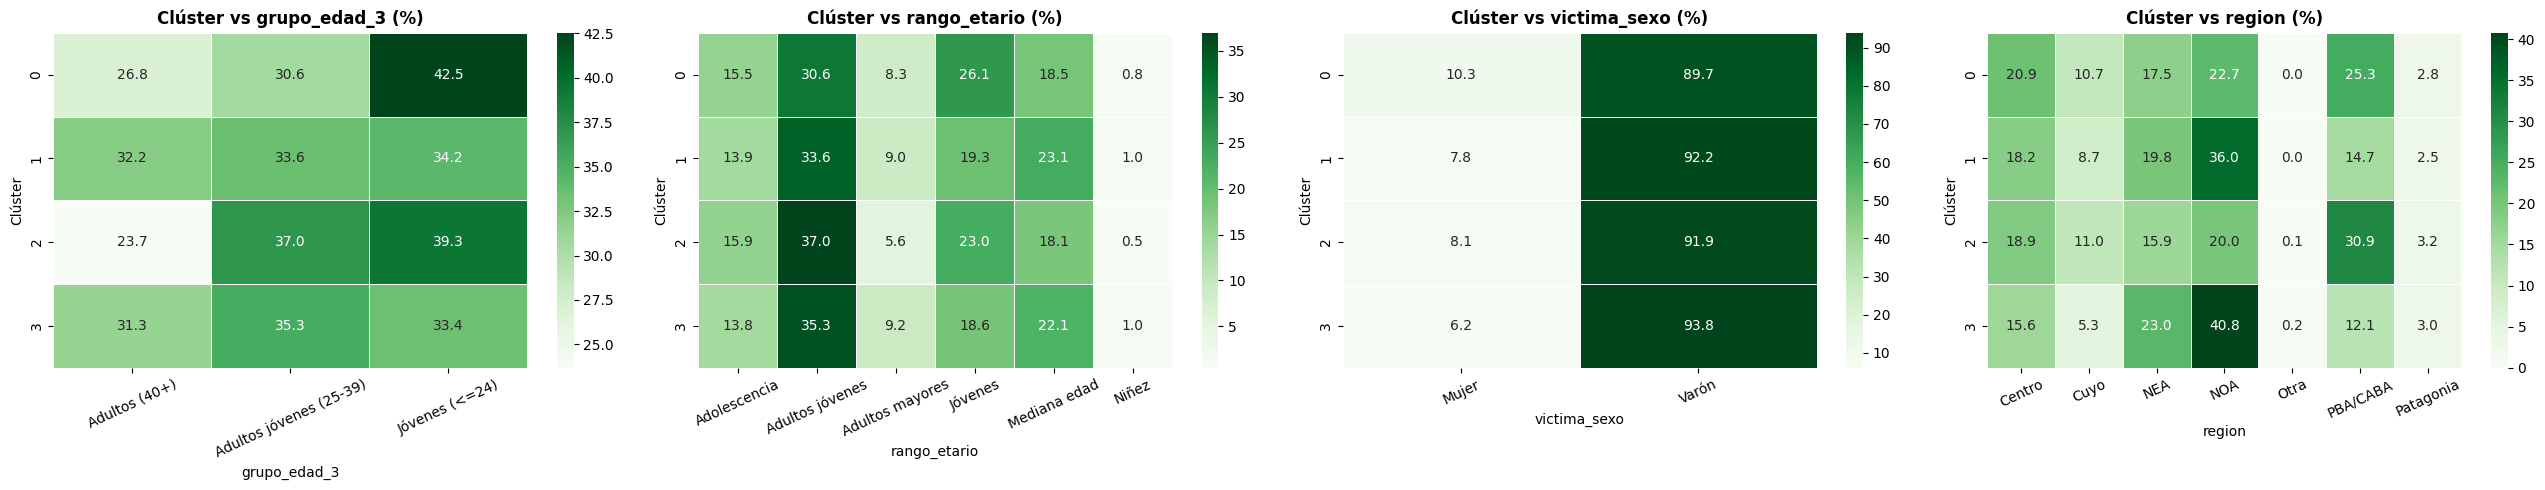

In [57]:
fig, axes = plt.subplots(1, len(vars_externas), figsize=(6.5 * len(vars_externas), 5))
axes = np.atleast_1d(axes)
for ax, ext_col in zip(axes, vars_externas):
    ct = pd.crosstab(df_modelo["cluster"], df_modelo[ext_col], normalize="index") * 100
    sns.heatmap(ct, annot=True, fmt=".1f", cmap="Greens", ax=ax, linewidths=0.5)
    ax.set_title(f"Clúster vs {ext_col} (%)", fontweight="bold")
    ax.set_ylabel("Clúster")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()